# Practica 2 · Machine Learning I
## IBM HR Analytics: rotacion de empleados
**Mineria de Datos · Facultad de Ingenieria, UNAM · Grupo 01 · Semestre 2027-1**  
**Equipo:** Lara Hernandez Angel Husiel, Lugo Manzano Rodrigo y Garcia Cortes Adolfo de Jesus.  
**Profesor:** Mtro. Gerardo Gabriel Carrasco Zuñiga.  
**Entrega:** 5 de octubre de 2026.

Para esta practica se utilizo la base de IBM HR Analytics, donde tenemos informacion de empleados y una columna que indica si hubo una baja. A partir de esto vamos a revisar los datos, preparar las variables y comparar cinco modelos. Posteriormente se explica lo que arrojo cada uno y se responden las preguntas de la guia.


Lo que buscamos es identificar que condiciones se relacionan con `Attrition = Yes` y que modelo permite reconocer mejor esa clase. En este caso se trata de un ejercicio con datos ficticios, por lo que los resultados sirven para estudiar la retencion y requieren una revision con datos reales antes de llevarlos a una empresa.

## 0. Entorno de trabajo


In [ ]:
import sys, json, time, warnings, hashlib, base64, zlib, io, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve)

SEED = 42
np.random.seed(SEED)
OUT = Path('evidencias_practica2')
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.0)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
versiones = {'Python':sys.version.split()[0], 'pandas':pd.__version__,
    'NumPy':np.__version__, 'scikit-learn':sklearn.__version__,
    'Matplotlib':matplotlib.__version__, 'Seaborn':sns.__version__}
display(pd.Series(versiones, name='Versión').to_frame())

def tabla(nombre, data):
    data.to_csv(OUT / f'{nombre}.csv', encoding='utf-8-sig')
    display(data)

def figura(nombre):
    plt.tight_layout()
    plt.savefig(OUT / f'{nombre}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

,Versión
Python,3.13.15
pandas,2.2.3
NumPy,2.1.3
scikit-learn,1.6.1
Matplotlib,3.10.0
Seaborn,0.13.2


## Parte 1. Seleccion y comprension de la base
**Archivo:** `WA_Fn-UseC_-HR-Employee-Attrition.csv`.  
**Fuente:** [IBM HR Analytics Employee Attrition & Performance, Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset).   
**Dimensiones:** 1,470 filas y 35 columnas.  
**Variable objetivo:** `Attrition`, donde `No = 0` y `Yes = 1`.

Cada fila representa a un empleado, donde se tienen datos como edad, ingreso, puesto, satisfaccion y años dentro de la empresa. Cabe mencionar que la descripcion de Kaggle indica que la base es ficticia y fue creada por cientificos de datos de IBM.

Ahora bien, la decision que podria apoyar este analisis, por ejemplo la carga de horas extra. Se eligio `Attrition` porque una baja es qie se reemplazar personal y capacitar a quien llega, ademas de perder experiencia. La clase que nos interesa es `Yes`, que es la baja del empleado.

In [ ]:
from google.colab import files
import pandas as pd
import hashlib
import io

archivos = files.upload()
nombre_archivo = next(iter(archivos))
contenido = archivos[nombre_archivo]

CSV_SHA256 = hashlib.sha256(contenido).hexdigest()
df = pd.read_csv(io.BytesIO(contenido))

assert df.shape == (1470, 35)
assert set(df['Attrition'].unique()) == {'Yes', 'No'}

y_eda = df['Attrition'].map({'No': 0, 'Yes': 1}).astype(int)

print('Archivo:', nombre_archivo)
print('Filas y columnas:', df.shape)
print('SHA-256:', CSV_SHA256)
display(df.head())

clases = (
    df['Attrition']
    .value_counts()
    .reindex(['No', 'Yes'])
    .to_frame('Empleados')
)

clases['Porcentaje'] = clases['Empleados'] / len(df) * 100
tabla('01_distribucion_objetivo', clases)


Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Archivo: WA_Fn-UseC_-HR-Employee-Attrition.csv
Filas y columnas: (1470, 35)
SHA-256: a5c31e38bd7fafc9bc333884eb181b06b41b8e5e488e8f7ccb27199fb3be7659


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,...,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,...,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,...,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,...,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,...,3,3,2,2,2,2


,Empleados,Porcentaje
Attrition,,
No,1233,83.8776
Yes,237,16.1224


## Parte 2. Analisis estadistico inicial
### 2.1. Tablas dinamicas y cubo de informacion
Para esto se uso `Attrition` con `OverTime`, `Department` y `JobRole`, lo que nos arroja tres tablas con lo satributos de:

-Permanencias.

-Bajas.

-Tamaño de cada grupo.

Ademas de esto se agrego una seccion que combina departamento y horas extra. En cada caso se calcula la tasa de bajas, esto porque comparar solamente los conteos podria hacer que un departamento pareciera tener mas riesgo. Ademas se genero un cubo por departamento y
horas extra.


In [ ]:
def resumen_rotacion(columnas):
    t = pd.crosstab([df[c] for c in columnas], df['Attrition']).reindex(columns=['No','Yes'], fill_value=0)
    t.columns = ['Permanencia (No)', 'Bajas (Yes)']
    t['Total'] = t.sum(axis=1)
    t['Tasa de bajas (%)'] = 100 * t['Bajas (Yes)'] / t['Total']
    return t.sort_values('Tasa de bajas (%)', ascending=False)
resumenes = {}
for c in ['OverTime','Department','JobRole']:
    display(Markdown(f'**Tabla dinámica: {c} × Attrition**'))
    resumenes[c] = resumen_rotacion([c])
    tabla(f'02_tabla_{c}', resumenes[c])
display(Markdown('**Cubo: Department × OverTime × Attrition**'))
tabla('02_cubo_departamento_horas_extra', resumen_rotacion(['Department','OverTime']))

**Tabla dinámica: OverTime × Attrition**

,Permanencia (No),Bajas (Yes),Total,Tasa de bajas (%)
OverTime,,,,
Yes,289,127,416,30.5288
No,944,110,1054,10.4364


**Tabla dinámica: Department × Attrition**

,Permanencia (No),Bajas (Yes),Total,Tasa de bajas (%)
Department,,,,
Sales,354,92,446,20.6278
Human Resources,51,12,63,19.0476
Research & Development,828,133,961,13.8398


**Tabla dinámica: JobRole × Attrition**

,Permanencia (No),Bajas (Yes),Total,Tasa de bajas (%)
JobRole,,,,
Sales Representative,50,33,83,39.7590
Laboratory Technician,197,62,259,23.9382
Human Resources,40,12,52,23.0769
Sales Executive,269,57,326,17.4847
Research Scientist,245,47,292,16.0959
Manufacturing Director,135,10,145,6.8966
Healthcare Representative,122,9,131,6.8702
Manager,97,5,102,4.9020
Research Director,78,2,80,2.5000


**Cubo: Department × OverTime × Attrition**

,,Permanencia (No),Bajas (Yes),Total,Tasa de bajas (%)
Department,OverTime,,,,
Sales,Yes,80,48,128,37.5000
Human Resources,Yes,12,5,17,29.4118
Research & Development,Yes,197,74,271,27.3063
Human Resources,No,39,7,46,15.2174
Sales,No,274,44,318,13.8365
Research & Development,No,631,59,690,8.5507


En el caso de horas extra, tenemos que una tasa de 30.53% contra a una tasa de 10.44% sin horas extra. En el caso de los departamentos, `Sales` llega con un 20.63%, mientras que `Research & Development` tiene 13.84%. Por puesto, `Sales Representative` tiene un 39.76%, no obstante, este solo tiene untotoal de 83 empleados. Po lo tanto, tanto el tamaño como la tasa se deben de analizar juntos para poder interpretar la comparacion.

### Estadistica descriptiva por clase
Despues de esto se obtuvo el promedio, minimo, maximo, desviacion estandar y cuartiles de todas las columnas numericas. Primero se muestran los resultados generales y despues se separan por `Attrition`, para ver como cambia la distribucion entre bajas y permanencias. En el caso de `EmployeeNumber`, el calculo se conserva en la salida completa, pero este en si, no se interpreta como una medida del trabajo, esto por que es un identificador. El csv
no dice en si cual es la moneda de ingreso, por lo que se conservan sus valores sin atribuirles pesos
mexicanos o alguna otra moneda.

In [ ]:
numericas_originales = df.select_dtypes(include='number').columns.tolist()
agg = ['count','mean','min','max','std','median']
descriptiva = df[numericas_originales].agg(agg).T
descriptiva['Q1'] = df[numericas_originales].quantile(.25)
descriptiva['Q3'] = df[numericas_originales].quantile(.75)
tabla('03_descriptiva_global', descriptiva)
por_clase = df.groupby('Attrition')[numericas_originales].describe().stack(level=0, future_stack=True)
tabla('03_descriptiva_por_clase', por_clase)

,count,mean,min,max,std,median,Q1,Q3
Age,"1,470.0000",36.9238,18.0000,60.0000,9.1354,36.0000,30.0000,43.0000
DailyRate,"1,470.0000",802.4857,102.0000,"1,499.0000",403.5091,802.0000,465.0000,"1,157.0000"
DistanceFromHome,"1,470.0000",9.1925,1.0000,29.0000,8.1069,7.0000,2.0000,14.0000
Education,"1,470.0000",2.9129,1.0000,5.0000,1.0242,3.0000,2.0000,4.0000
EmployeeCount,"1,470.0000",1.0000,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000
EmployeeNumber,"1,470.0000","1,024.8653",1.0000,"2,068.0000",602.0243,"1,020.5000",491.2500,"1,555.7500"
EnvironmentSatisfaction,"1,470.0000",2.7218,1.0000,4.0000,1.0931,3.0000,2.0000,4.0000
HourlyRate,"1,470.0000",65.8912,30.0000,100.0000,20.3294,66.0000,48.0000,83.7500
JobInvolvement,"1,470.0000",2.7299,1.0000,4.0000,0.7116,3.0000,2.0000,3.0000
JobLevel,"1,470.0000",2.0639,1.0000,5.0000,1.1069,2.0000,1.0000,3.0000


count        mean        std  \
Attrition                                                              
No        Age                      1,233.0000     37.5612     8.8884   
          DailyRate                1,233.0000    812.5045   403.2084   
          DistanceFromHome         1,233.0000      8.9157     8.0126   
          Education                1,233.0000      2.9270     1.0270   
          EmployeeCount            1,233.0000      1.0000     0.0000   
          EmployeeNumber           1,233.0000  1,027.6561   606.2171   
          EnvironmentSatisfaction  1,233.0000      2.7713     1.0711   
          HourlyRate               1,233.0000     65.9521    20.3808   
          JobInvolvement           1,233.0000      2.7705     0.6920   
          JobLevel                 1,233.0000      2.1460     1.1179   
          JobSatisfaction          1,233.0000      2.7786     1.0933   
          MonthlyIncome            1,233.0000  6,832.7397 4,818.2080   
          MonthlyRate              1,233.0000 14,265.7794 7,102.2607   
          NumCompaniesWorked       1,233.0000      2.6456     2.4601   
          PercentSalaryHike        1,233.0000     15.2311     3.6395   
          PerformanceRating        1,233.0000      3.1533     0.3604   
          RelationshipSatisfaction 1,233.0000      2.7340     1.0716   
          StandardHours            1,233.0000     80.0000     0.0000   
          StockOptionLevel         1,233.0000      0.8451     0.8420   
          TotalWorkingYears        1,233.0000     11.8629     7.7607   
          TrainingTimesLastYear    1,233.0000      2.8329     1.2936   
          WorkLifeBalance          1,233.0000      2.7810     0.6819   
          YearsAtCompany           1,233.0000      7.3690     6.0963   
          YearsInCurrentRole       1,233.0000      4.4842     3.6494   
          YearsSinceLastPromotion  1,233.0000      2.2344     3.2348   
          YearsWithCurrManager     1,233.0000      4.3674     3.5941   
Yes       Age                        237.0000     33.6076     9.6893   
          DailyRate                  237.0000    750.3629   401.8995   
          DistanceFromHome           237.0000     10.6329     8.4525   
          Education                  237.0000      2.8397     1.0082   
          EmployeeCount              237.0000      1.0000     0.0000   
          EmployeeNumber             237.0000  1,010.3460   580.7506   
          EnvironmentSatisfaction    237.0000      2.4641     1.1698   
          HourlyRate                 237.0000     65.5738    20.1000   
          JobInvolvement             237.0000      2.5190     0.7734   
          JobLevel                   237.0000      1.6371     0.9406   
          JobSatisfaction            237.0000      2.4684     1.1181   
          MonthlyIncome              237.0000  4,787.0928 3,640.2104   
          MonthlyRate                237.0000 14,559.3080 7,208.1533   
          NumCompaniesWorked         237.0000      2.9409     2.6785   
          PercentSalaryHike          237.0000     15.0970     3.7703   
          PerformanceRating          237.0000      3.1561     0.3637   
          RelationshipSatisfaction   237.0000      2.5992     1.1254   
          StandardHours              237.0000     80.0000     0.0000   
          StockOptionLevel           237.0000      0.5274     0.8564   
          TotalWorkingYears          237.0000      8.2447     7.1692   
          TrainingTimesLastYear      237.0000      2.6245     1.2548   
          WorkLifeBalance            237.0000      2.6582     0.8165   
          YearsAtCompany             237.0000      5.1308     5.9500   
          YearsInCurrentRole         237.0000      2.9030     3.1748   
          YearsSinceLastPromotion    237.0000      1.9451     3.1531   
          YearsWithCurrManager       237.0000      2.8523     3.1433   

                                          min        25%         50%  \
Attrition                                                              
No     

### Graficas comparativas
Ahora bien, para revisar los resultados de las tabblas se graficaron las tasas de bajas por horas extra y departamento. Tambien se compararon los ingresos y la antigüedad mediante diagramas de caja. La linea central
indica la mediana y la caja reune el 50% central de los registros, los puntos extremos requieren
contexto.

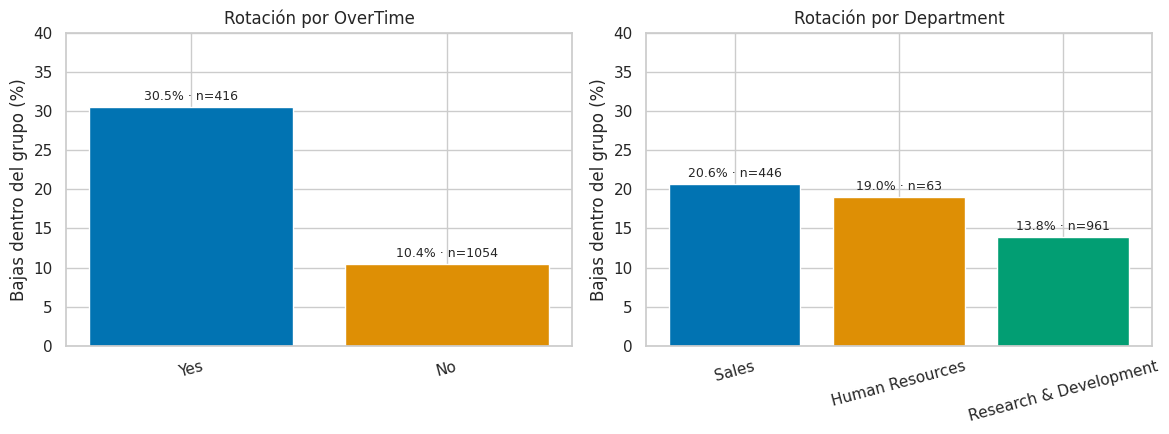

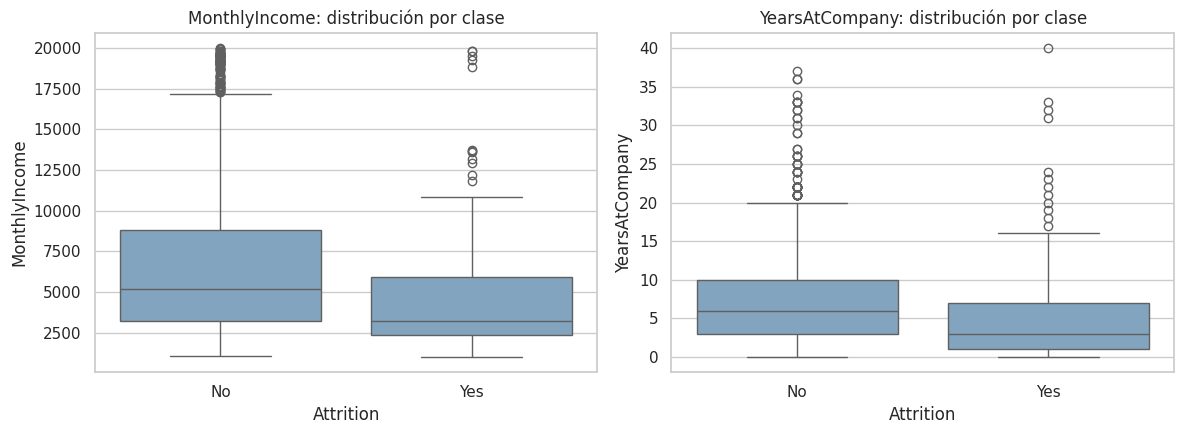

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
for ax, c in zip(axes, ['OverTime','Department']):
    t = resumenes[c]
    bars = ax.bar(t.index.astype(str), t['Tasa de bajas (%)'], color=sns.color_palette('colorblind', len(t)))
    ax.set(title=f'Rotación por {c}', ylabel='Bajas dentro del grupo (%)', ylim=(0,40))
    ax.tick_params(axis='x', rotation=15)
    ax.bar_label(bars, labels=[f'{r:.1f}% · n={n}' for r,n in zip(t['Tasa de bajas (%)'],t['Total'])], padding=3, fontsize=9)
figura('04_tasas_rotacion')
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax,c in zip(axes, ['MonthlyIncome','YearsAtCompany']):
    sns.boxplot(data=df, x='Attrition', y=c, order=['No','Yes'], ax=ax, color='#78a6c8')
    ax.set(title=f'{c}: distribución por clase', xlabel='Attrition', ylabel=c)
figura('04_distribuciones_por_clase')

Interpretacion:

La primera parte nos dice que 237 bajas de 1470 empleados lo que es un 16.1%, por lo que tenemos una clase minoritaria.

Ahora bien, con horas extra la tasa de bajas es 30.5%, frente a 10.4% sin horas extra.

`Sales` es el departamento con mayor tasa, la cual tiene un 20.6%, por lo que también hay que revisar cuántos empleados contiene.

`Sales Representative` es el puesto con mayor tasa (39.8%, n=83).

Al comparar ingresos, el promedio es 4,787.09 en bajas y 6,832.74 en permanencias, aqui tenemos un problema, debido a que el archiv no indica la unidad monetaria.

En el caso de la antigüedad, la media es 5.13 años en bajas y 7.37 en permanencias.

##Lo que se tieen aqui es una relacion con carga laboral, remuneracion y trayectoria, para comprobar el efecto de un cambio se necesitaria otro analisis.

## Parte 3. EDA y preparacion de variables

Para esto se reviso cada columna con conteo de nulos, tipo de dato, categorias y cantidad de valores
diferentes.

Se logro identificar 26 columnas almacenadas como enteros y nueve como texto, con esto despues de separar la etiqueta y retirar las cuatro descartadas quedan 23 columnas numericas y siete nominales.

Ademas se reviso que la edad estuviera entre 18 y 100 años, que el ingreso mensual fuera positivo y que los años en la empresa no superaran la experiencia total.

Se compararon tambien años en el puesto, con el gerente y desde la promocion contra los años en la empresa, y las cinco escalas de satisfaccion o participacion contra el rango de 1 a 4. Las once reglas arrojaron cero casos para revisar.

Las edades que se tienen van de 18 a 60 años y los valores extremos se conservaron.

In [ ]:
calidad = pd.DataFrame({'Tipo':df.dtypes.astype(str), 'Nulos':df.isna().sum(),
    'Valores distintos':df.nunique(dropna=False)})
tabla('05_calidad_columnas', calidad)
print('Nulos totales:', int(df.isna().sum().sum()))
print('Filas duplicadas completas:', int(df.duplicated().sum()))
print('EmployeeNumber repetidos:', int(df['EmployeeNumber'].duplicated().sum()))
reglas = {
    'Edad entre 18 y 100': df['Age'].between(18,100),
    'Ingreso mensual positivo': df['MonthlyIncome'].gt(0),
    'Años en empresa no mayores que experiencia total': df['YearsAtCompany'].le(df['TotalWorkingYears']),
    'Años en puesto no mayores que años en empresa': df['YearsInCurrentRole'].le(df['YearsAtCompany']),
    'Años con gerente no mayores que años en empresa': df['YearsWithCurrManager'].le(df['YearsAtCompany']),
    'Años desde promoción no mayores que años en empresa': df['YearsSinceLastPromotion'].le(df['YearsAtCompany']),
}
for c in ['EnvironmentSatisfaction','JobSatisfaction','RelationshipSatisfaction','JobInvolvement','WorkLifeBalance']:
    reglas[f'{c}: escala 1 a 4'] = df[c].between(1,4)
auditoria_reglas = pd.DataFrame({'Regla':list(reglas), 'Casos para revisar':[int((~v).sum()) for v in reglas.values()]})
tabla('05_reglas_plausibilidad', auditoria_reglas)
for c in df.select_dtypes(include=['object','string']).columns:
    print(c, ':', sorted(df[c].dropna().unique().tolist()))

,Tipo,Nulos,Valores distintos
Age,int64,0,43
Attrition,object,0,2
BusinessTravel,object,0,3
DailyRate,int64,0,886
Department,object,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
EducationField,object,0,6
EmployeeCount,int64,0,1
EmployeeNumber,int64,0,1470


Nulos totales: 0
Filas duplicadas completas: 0
EmployeeNumber repetidos: 0


,Regla,Casos para revisar
0,Edad entre 18 y 100,0
1,Ingreso mensual positivo,0
2,Años en empresa no mayores que experiencia total,0
3,Años en puesto no mayores que años en empresa,0
4,Años con gerente no mayores que años en empresa,0
5,Años desde promoción no mayores que años en em...,0
6,EnvironmentSatisfaction: escala 1 a 4,0
7,JobSatisfaction: escala 1 a 4,0
8,RelationshipSatisfaction: escala 1 a 4,0
9,JobInvolvement: escala 1 a 4,0


Attrition : ['No', 'Yes']
BusinessTravel : ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department : ['Human Resources', 'Research & Development', 'Sales']
EducationField : ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender : ['Female', 'Male']
JobRole : ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus : ['Divorced', 'Married', 'Single']
Over18 : ['Y']
OverTime : ['No', 'Yes']


## Variables seleccionadas y descartadas
Se utilizaron 30 predictores, donde se incluyen condiciones del puesto, satisfaccion, compensacion, formacion y trayectoria. La razon por la que se conservaron es que permiten revisar distintas condiciones laborales y comparar los cinco modelos con la misma informacion.

En el caso de `EmployeeNumber`, se descarto porque identifica al empleado. Tambien se retiraron `EmployeeCount`, `Over18` y `StandardHours`, porque tienen un mismo valor en todas las filas. `Attrition` se separo como etiqueta. Las escalas de satisfaccion y nivel se mantuvieron como numeros ordinales, lo que supone una distancia igual entre niveles, las categorias sin orden se convierten con one-hot.

Cabe mencionar que `Gender`, `Age` y `MaritalStatus` se conservan para esta comparacion, pero se necesita revisar si se es que llegaran a tener sesgos. Esto por que, que una columna ayude a predecir no significa que sea adecuada para decidir sobre una persona. Por esto se agrego una parte por genero y se propone comparar despues una version sin estos atributos.

In [ ]:
DROP = ['EmployeeNumber','EmployeeCount','Over18','StandardHours']
ordinales = ['Education','EnvironmentSatisfaction','JobInvolvement','JobLevel',
    'JobSatisfaction','PerformanceRating','RelationshipSatisfaction','StockOptionLevel','WorkLifeBalance']
razones_drop = {'EmployeeNumber':'Identificador del registro; no condición laboral',
    'EmployeeCount':'Constante: 1', 'Over18':'Constante: Y', 'StandardHours':'Constante: 80'}
razones = {
    'Age':'Etapa de trayectoria; revisar sesgos por edad', 'BusinessTravel':'Exposición a viajes laborales',
    'DailyRate':'Compensación diaria', 'Department':'Área organizacional', 'DistanceFromHome':'Distancia asociada al traslado',
    'Education':'Nivel educativo ordinal', 'EducationField':'Campo de formación',
    'EnvironmentSatisfaction':'Satisfacción con el entorno', 'Gender':'Atributo demográfico; auditar sesgos',
    'HourlyRate':'Compensación por hora', 'JobInvolvement':'Participación en el trabajo', 'JobLevel':'Nivel del puesto',
    'JobRole':'Tipo de puesto', 'JobSatisfaction':'Satisfacción laboral', 'MaritalStatus':'Contexto personal; auditar sesgos',
    'MonthlyIncome':'Ingreso mensual', 'MonthlyRate':'Tarifa mensual registrada', 'NumCompaniesWorked':'Trayectoria entre empresas',
    'OverTime':'Carga laboral por horas extra', 'PercentSalaryHike':'Variación salarial', 'PerformanceRating':'Evaluación ordinal de desempeño',
    'RelationshipSatisfaction':'Satisfacción con relaciones', 'StockOptionLevel':'Nivel de beneficios accionarios',
    'TotalWorkingYears':'Experiencia acumulada', 'TrainingTimesLastYear':'Frecuencia de capacitación',
    'WorkLifeBalance':'Equilibrio trabajo-vida', 'YearsAtCompany':'Antigüedad', 'YearsInCurrentRole':'Permanencia en el puesto',
    'YearsSinceLastPromotion':'Tiempo desde promoción', 'YearsWithCurrManager':'Continuidad con la gerencia'}
X = df.drop(columns=['Attrition']+DROP).copy()
y = y_eda.copy()
NUM = X.select_dtypes(include='number').columns.tolist()
CAT = [c for c in X if c not in NUM]
variables = []
for c in df:
    tipo = ('Objetivo' if c=='Attrition' else 'Identificador' if c=='EmployeeNumber' else
        'Descartable constante' if c in DROP else 'Categórica nominal' if c in CAT else
        'Numérica ordinal' if c in ordinales else 'Numérica')
    variables.append({'Variable':c,'Clasificación':tipo,'Uso':'Etiqueta' if c=='Attrition' else 'Descartada' if c in DROP else 'Predictora',
        'Tratamiento':'Separar y mapear No=0, Yes=1' if c=='Attrition' else 'Eliminar' if c in DROP else 'One-hot' if c in CAT else 'Imputar; escalar en NB/KNN/MLP',
        'Justificación':razones_drop.get(c,razones.get(c,'Clase de clasificación'))})
variables = pd.DataFrame(variables)
tabla('06_seleccion_variables', variables)
print(f'Predictores: {X.shape[1]} originales = {len(NUM)} numéricos y {len(CAT)} nominales')
assert X.shape[1]==30 and 'Attrition' not in X and not set(DROP).intersection(X.columns)

,Variable,Clasificación,Uso,Tratamiento,Justificación
0,Age,Numérica,Predictora,Imputar; escalar en NB/KNN/MLP,Etapa de trayectoria; revisar sesgos por edad
1,Attrition,Objetivo,Etiqueta,"Separar y mapear No=0, Yes=1",Clase de clasificación
2,BusinessTravel,Categórica nominal,Predictora,One-hot,Exposición a viajes laborales
3,DailyRate,Numérica,Predictora,Imputar; escalar en NB/KNN/MLP,Compensación diaria
4,Department,Categórica nominal,Predictora,One-hot,Área organizacional
5,DistanceFromHome,Numérica,Predictora,Imputar; escalar en NB/KNN/MLP,Distancia asociada al traslado
6,Education,Numérica ordinal,Predictora,Imputar; escalar en NB/KNN/MLP,Nivel educativo ordinal
7,EducationField,Categórica nominal,Predictora,One-hot,Campo de formación
8,EmployeeCount,Descartable constante,Descartada,Eliminar,Constante: 1
9,EmployeeNumber,Identificador,Descartada,Eliminar,Identificador del registro; no condición laboral


Predictores: 30 originales = 23 numéricos y 7 nominales


### Transformacion de las variables
Primero se separan los datos y despues se ajustan las transformaciones dentro de entrenamiento. Para esto se utilizaron `Pipeline` y `ColumnTransformer`, de manera que en cada fold la mediana, el escalado y las categorias se aprenden solamente con las filas que se usan para entrenar. En prueba se aplica la transformacion que ya quedo ajustada.

Las columnas numericas se atribuye a la mediana y se escalan con `StandardScaler` para NB, KNN y la red neuronal. Las nominales son parte, ahora con la moda y se convierten con `OneHotEncoder`.

Actualmente no hay nulos, pero se deja que hacer si aparecen. En el arbol y Random Forest se conservan las unidades originales de las numericas, para que sus cortes se puedan leer con mayor facilidad.

Las siete nominales generan 28 indicadores: viajes (3), departamento (3), formacion (6), genero (2), puesto (9), estado civil (3) y horas extra (2). Junto con las 23 numericas se tienen 51 entradas transformadas.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.30,random_state=SEED,stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
particion = pd.DataFrame({'Conjunto':['Entrenamiento','Prueba'],
    'Registros':[len(y_train),len(y_test)],'No':[int((y_train==0).sum()),int((y_test==0).sum())],
    'Yes':[int(y_train.sum()),int(y_test.sum())],
    'Porcentaje Yes':[100*y_train.mean(),100*y_test.mean()]})
tabla('07_particion_70_30', particion)

def preprocesador(escalar=True):
    pasos=[('imputar',SimpleImputer(strategy='median'))]
    if escalar: pasos.append(('escalar',StandardScaler()))
    # Compatibilidad con versiones anteriores y actuales de scikit-learn.
    kwargs={'handle_unknown':'ignore'}
    kwargs['sparse_output' if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else 'sparse']=False
    cat=Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(**kwargs))])
    return ColumnTransformer([('num',Pipeline(pasos),NUM),('cat',cat,CAT)],sparse_threshold=0)

preview = preprocesador().fit(X_train)
nombres_transformados = preview.get_feature_names_out()
X_train_previa = preview.transform(X_train)
print('Forma antes:', X_train.shape, '| Después de one-hot:', X_train_previa.shape)
display(pd.DataFrame(X_train_previa[:5],columns=nombres_transformados).iloc[:,:12])
tabla('07_columnas_transformadas',pd.DataFrame({'Nombre transformado':nombres_transformados}))
# preview es solo evidencia; cada modelo y cada fold ajustan su propio preprocesador.

,Conjunto,Registros,No,Yes,Porcentaje Yes
0,Entrenamiento,1029,863,166,16.1322
1,Prueba,441,370,71,16.0998


Forma antes: (1029, 30) | Después de one-hot: (1029, 51)


,num__Age,num__DailyRate,num__DistanceFromHome,num__Education,num__EnvironmentSatisfaction,num__HourlyRate,num__JobInvolvement,num__JobLevel,num__JobSatisfaction,num__MonthlyIncome,num__MonthlyRate,num__NumCompaniesWorked
0,-1.9589,-0.4140,-0.0366,-0.8661,0.2705,-0.5479,0.3780,-0.9984,-1.5389,-0.8670,-1.0090,-0.6891
1,-0.4307,1.1761,0.6990,-1.8358,-0.6512,-0.4496,0.3780,0.8460,0.2647,1.5321,1.4048,1.7146
2,1.6433,1.2968,0.2086,1.0734,1.1922,0.8290,0.3780,-0.0762,0.2647,-0.7375,1.0177,2.1152
3,-1.0856,-0.5498,-0.8948,0.1037,1.1922,1.0749,0.3780,-0.9984,1.1664,-0.8609,-1.1301,-0.2885
4,-0.3215,-1.2744,-0.8948,1.0734,0.2705,0.4848,0.3780,-0.9984,0.2647,-0.9367,-0.4360,1.3140


,Nombre transformado
0,num__Age
1,num__DailyRate
2,num__DistanceFromHome
3,num__Education
4,num__EnvironmentSatisfaction
5,num__HourlyRate
6,num__JobInvolvement
7,num__JobLevel
8,num__JobSatisfaction
9,num__MonthlyIncome


Para esto, la primera tabla nos muestra la base en los conjuntos de entrenamiento y prueba.
Ahora bien, el conjunto de entrenamiento quedo teniendo por 1029 registros y el de prueba por 441.
En el caso de entrenamiento la tasa de rotación es de 16.13%, mientras que en prueba se tiene un 16.09%.
Se pasó de tener 30 columnas originales a 51 atributos finales debido a la codificación one-hot de las nominales.

Finalmente, los valores resultantes muestran decimales, confirmando que el escalado se hizo correctamente.

## Parte 4. Aplicación de primeros modelos de Machine Learning

### 4.1. División de datos en entrenamiento y prueba

Para esto se utilizó una partición estratificada de **70/30**, donde quedaron **1,029 registros para entrenamiento y 441 para prueba**.

In [ ]:
# 4.1. Definición del preprocesador y División de datos
transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocess = ColumnTransformer(transformers=[
    ('num', transformador_numerico, NUM),
    ('cat', transformador_categorico, CAT)
], remainder='passthrough')

#  Partición estratificada de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

particion = pd.DataFrame([
    {'Conjunto': 'Entrenamiento', 'Registros': len(y_train), 'No': (y_train==0).sum(), 'Yes': (y_train==1).sum(), 'Porcentaje Yes': (y_train==1).mean()*100},
    {'Conjunto': 'Prueba', 'Registros': len(y_test), 'No': (y_test==0).sum(), 'Yes': (y_test==1).sum(), 'Porcentaje Yes': (y_test==1).mean()*100}
])
tabla('07_particion_datos', particion)

,Conjunto,Registros,No,Yes,Porcentaje Yes
0,Entrenamiento,1029,863,166,16.1322
1,Prueba,441,370,71,16.0998


### 4.2. Entrenamiento y configuración de modelos

Dentro de entrenamiento se compararon unas cuantas configuraciones mediante tres folds estratificados. Se eligió **F1 de `Yes`** como criterio principal y se conservó el umbral de 0.5. Posteriormente, la mejor configuración de cada modelo se ajustó con todo entrenamiento y se evaluó en la prueba reservada.

| Modelo | Qué hace | Preparación y configuración revisada |
| :--- | :--- | :--- |
| Naive Bayes gaussiano | Estima distribuciones por clase | Escalado y suavizado de varianza; one-hot aproxima entradas gaussianas |
| K-Nearest Neighbor | Compara vecinos por distancia | Escalado, k=5/11 y voto por distancia |
| Árbol de decisión | Genera reglas mediante cortes | Profundidad 3/5, mínimo 10 por hoja y pesos balanceados |
| Random Forest | Combina 200 árboles | Profundidad limitada o libre, mínimo por hoja y pesos balanceados opcionales |
| Red neuronal MLP | Aprende relaciones mediante capas | Escalado, capas de 20 y 10 neuronas, regularización L2 y Adam |

Además de esto se agregó una referencia que siempre predice `No`. Lo que nos permite ver es cuánta exactitud se puede obtener por la clase mayoritaria, aun cuando no se detecte ninguna baja. No se modificaron las proporciones de la prueba ni se aplicó sobremuestreo sobre toda la base.

In [ ]:
# 4.2. Entrenamieto
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

CONFIG = {
    'Naive Bayes': (GaussianNB(), {'modelo__var_smoothing': [.01, .1]}, True),
    'K-Nearest Neighbor': (KNeighborsClassifier(weights='distance'), {'modelo__n_neighbors': [5, 11]}, True),
    'Árbol de Decisión': (DecisionTreeClassifier(min_samples_leaf=10, class_weight='balanced', random_state=SEED), {'modelo__max_depth': [3, 5]}, False),
    'Random Forest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=SEED, n_jobs=1),
                      {'modelo__max_depth': [8, None], 'modelo__class_weight': [None, 'balanced_subsample']}, False),
    'Red Neuronal': (MLPClassifier(hidden_layer_sizes=(20,10), max_iter=800, random_state=SEED, early_stopping=False),
                     {'modelo__alpha': [.01, 1.0]}, True)
}

modelos, busquedas, filas_cv, alertas = {}, {}, [], []

for nombre, (estimador, parametros, escalar) in CONFIG.items():
    inicio = time.perf_counter()

    pipe = Pipeline([('preprocess', preprocess), ('modelo', estimador)])

    busqueda = GridSearchCV(pipe, parametros, scoring='f1', cv=CV, n_jobs=1, refit=True, error_score='raise')

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        busqueda.fit(X_train, y_train)

    for w in avisos:
        if issubclass(w.category, ConvergenceWarning):
            alertas.append({'Modelo': nombre, 'Aviso': str(w.message)})

    modelos[nombre] = busqueda.best_estimator_
    busquedas[nombre] = busqueda
    i = busqueda.best_index_

    filas_cv.append({
        'Modelo': nombre,
        'F1 CV': busqueda.best_score_,
        'Desviación CV': busqueda.cv_results_['std_test_score'][i],
        'Parámetros': str(busqueda.best_params_),
        'Segundos': time.perf_counter() - inicio
    })
    print(f"{nombre}: F1 CV={busqueda.best_score_:.4f}; {busqueda.best_params_}", flush=True)

cv_resultados = pd.DataFrame(filas_cv).sort_values('F1 CV', ascending=False).reset_index(drop=True)
seleccion_cv = cv_resultados.iloc[0]['Modelo']
tabla('08_validacion_cruzada', cv_resultados)

print(f"\nModelo seleccionado antes de evaluar prueba: {seleccion_cv}")
if alertas:
    tabla('08_avisos_convergencia', pd.DataFrame(alertas).drop_duplicates())
else:
    print('Sin advertencias de convergencia en la búsqueda.')

Naive Bayes: F1 CV=0.4931; {'modelo__var_smoothing': 0.1}
K-Nearest Neighbor: F1 CV=0.1581; {'modelo__n_neighbors': 5}
Árbol de Decisión: F1 CV=0.4167; {'modelo__max_depth': 5}
Random Forest: F1 CV=0.4936; {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': None}
Red Neuronal: F1 CV=0.5134; {'modelo__alpha': 1.0}


,Modelo,F1 CV,Desviación CV,Parámetros,Segundos
0,Red Neuronal,0.5134,0.0271,{'modelo__alpha': 1.0},8.1518
1,Random Forest,0.4936,0.0152,"{'modelo__class_weight': 'balanced_subsample',...",10.3702
2,Naive Bayes,0.4931,0.0119,{'modelo__var_smoothing': 0.1},0.3648
3,Árbol de Decisión,0.4167,0.0091,{'modelo__max_depth': 5},0.3650
4,K-Nearest Neighbor,0.1581,0.0267,{'modelo__n_neighbors': 5},0.3962



Modelo seleccionado antes de evaluar prueba: Red Neuronal
Sin advertencias de convergencia en la búsqueda.


### 4.3. Evaluación de los modelos

La **exactitud** indica cuántas predicciones fueron correctas en total. La **precisión de Yes** nos dice cuántas alertas sí correspondían a bajas; el **recall de Yes**, cuántas de las bajas reales se detectaron. **F1** reúne precisión y recall. También se calcula **ROC-AUC** con las probabilidades y **AP**, que resume la curva precision-recall. El F1 ponderado se deja en la salida adicional para comparar con el ejemplo de la guía.

In [ ]:
# 4.3 Evaluación de modelos y gráficas
predicciones, probabilidades = {}, {}

def metricas(nombre, clf, baseline=False):
    pred = clf.predict(X_test)
    p = clf.predict_proba(X_test)[:, list(clf.classes_).index(1)]

    predicciones[nombre] = pred
    probabilidades[nombre] = p

    return {
        'Modelo': nombre,
        'Variables utilizadas': 'Clase mayoritaria' if baseline else f'30 originales; {len(clf.named_steps["preprocess"].get_feature_names_out())} transformadas',
        'Exactitud': accuracy_score(y_test, pred),
        'Precisión': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, p),
        'AP': average_precision_score(y_test, p),
        'F1 ponderado': f1_score(y_test, pred, average='weighted', zero_division=0),
        'F1 entrenamiento': f1_score(y_train, clf.predict(X_train), zero_division=0)
    }

# Evaluacion
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
filas = [metricas('Baseline: siempre No', baseline, True)]

for nombre, clf in modelos.items():
    filas.append(metricas(nombre, clf))
    display(Markdown(f'**{nombre}: reporte completo en prueba**'))
    reporte = pd.DataFrame(
        classification_report(y_test, predicciones[nombre], target_names=['No (permanencia)', 'Yes (baja)'], zero_division=0, output_dict=True)
    ).T
    tabla('09_reporte_' + nombre.replace(' ', '_'), reporte)

resultados = pd.DataFrame(filas)


**Naive Bayes: reporte completo en prueba**

,precision,recall,f1-score,support
No (permanencia),0.9164,0.8000,0.8543,370.0000
Yes (baja),0.3729,0.6197,0.4656,71.0000
accuracy,0.7710,0.7710,0.7710,0.7710
macro avg,0.6446,0.7099,0.6599,441.0000
weighted avg,0.8289,0.7710,0.7917,441.0000


**K-Nearest Neighbor: reporte completo en prueba**

,precision,recall,f1-score,support
No (permanencia),0.8541,0.9811,0.9132,370.0000
Yes (baja),0.5625,0.1268,0.2069,71.0000
accuracy,0.8435,0.8435,0.8435,0.8435
macro avg,0.7083,0.5539,0.5601,441.0000
weighted avg,0.8072,0.8435,0.7995,441.0000


**Árbol de Decisión: reporte completo en prueba**

,precision,recall,f1-score,support
No (permanencia),0.9103,0.7676,0.8328,370.0000
Yes (baja),0.3333,0.6056,0.4300,71.0000
accuracy,0.7415,0.7415,0.7415,0.7415
macro avg,0.6218,0.6866,0.6314,441.0000
weighted avg,0.8174,0.7415,0.7680,441.0000


**Random Forest: reporte completo en prueba**

,precision,recall,f1-score,support
No (permanencia),0.8606,0.9514,0.9037,370.0000
Yes (baja),0.4375,0.1972,0.2718,71.0000
accuracy,0.8299,0.8299,0.8299,0.8299
macro avg,0.6491,0.5743,0.5878,441.0000
weighted avg,0.7925,0.8299,0.8020,441.0000


**Red Neuronal: reporte completo en prueba**

,precision,recall,f1-score,support
No (permanencia),0.8984,0.9324,0.9151,370.0000
Yes (baja),0.5614,0.4507,0.5000,71.0000
accuracy,0.8549,0.8549,0.8549,0.8549
macro avg,0.7299,0.6916,0.7076,441.0000
weighted avg,0.8442,0.8549,0.8483,441.0000


En las matrices, las filas corresponden a la clase real y las columnas a la predicción: `[[TN, FP], [FN, TP]]`. En este caso un falso negativo es una baja que no se detectó, mientras que un falso positivo es una alerta sobre un empleado que permaneció.

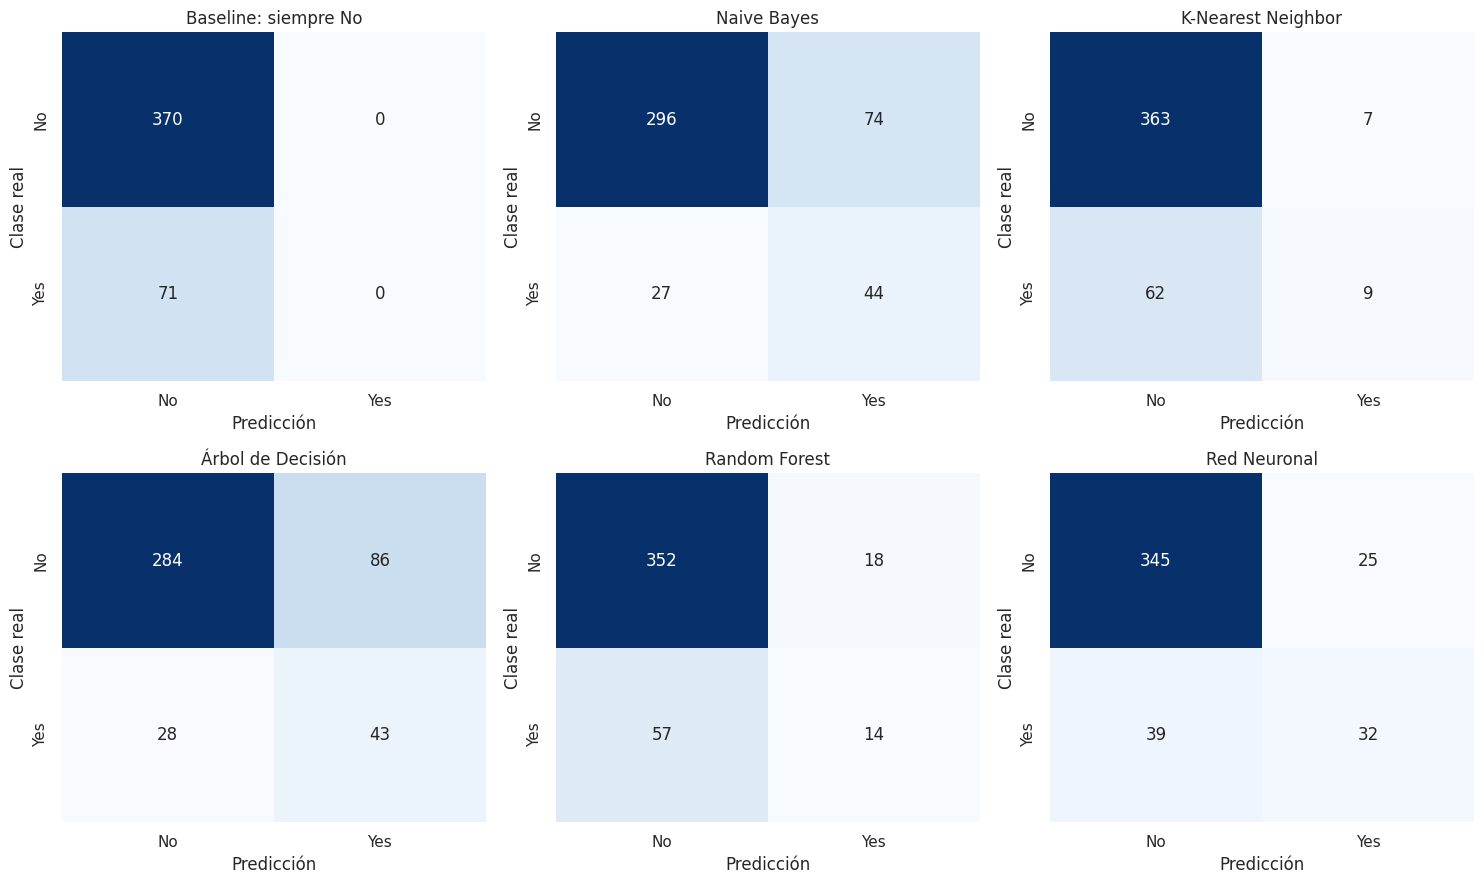

In [ ]:
# Matrices de Confusión
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, nombre in zip(axes.flat, resultados['Modelo']):
    cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    ax.set(title=nombre, xlabel='Predicción', ylabel='Clase real')

    pd.DataFrame(cm, index=['Real No', 'Real Yes'], columns=['Pred No', 'Pred Yes']).to_csv(OUT / ('09_matriz_' + nombre.replace(' ', '_') + '.csv'))

plt.tight_layout()
figura('09_matrices_confusion')

Para las curvas se utilizan las probabilidades, porque las etiquetas por sí solas no permiten revisar distintos umbrales. Esto responde a la instrucción de agregar la métrica de ROC o AUC para revisar la capacidad de discriminación del modelo.

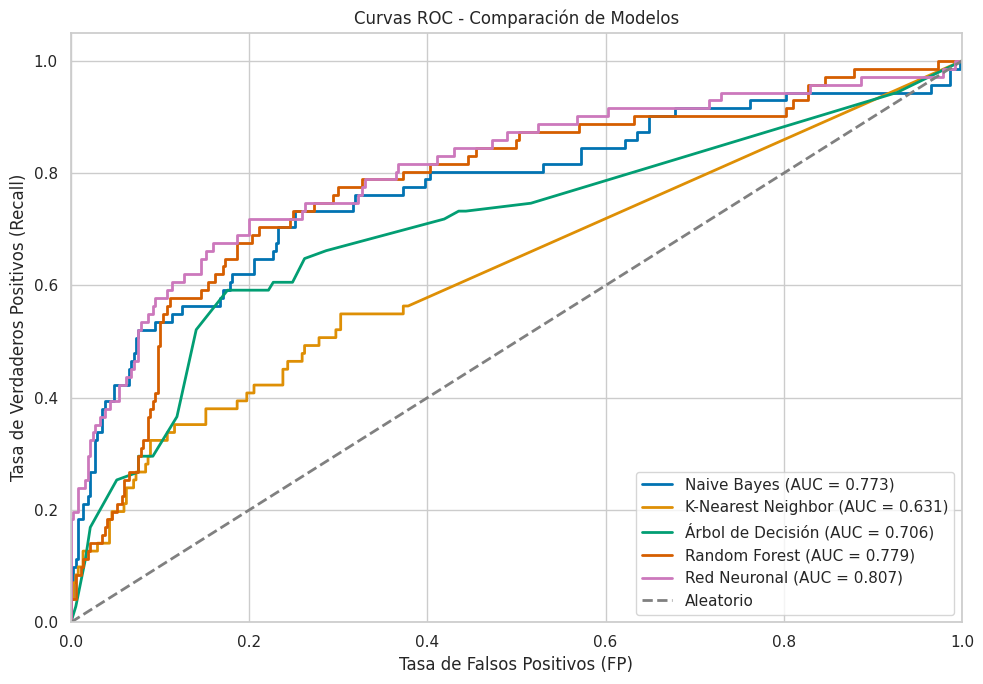

In [ ]:
#Graficar Curvas ROC
plt.figure(figsize=(10, 7))

for nombre in modelos.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilidades[nombre])
    auc_val = roc_auc_score(y_test, probabilidades[nombre])
    plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {auc_val:.3f})')

# Línea base aleatoria
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Aleatorio')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FP)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curvas ROC - Comparación de Modelos')
plt.legend(loc="lower right")
figura('09_curvas_roc')

## Parte 5. Comparación de modelos

Ahora bien, el cuadro siguiente reúne exactitud, precisión, recall y F1 de prueba. Las tres últimas métricas corresponden a bajas (`Yes`), no a un promedio de las clases. En la columna de variables se indican las 30 originales y las transformadas (el conjunto completo se documentó en pasos anteriores).

**Tabla 10: Comparación en los 441 registros de prueba**

,Modelo,Variables utilizadas,Exactitud,Precisión,Recall,F1-score,Interpretación breve
0,Baseline: siempre No,Clase mayoritaria,0.8390,0.0000,0.0000,0.0000,Detecta 0/71 bajas; 0 falsas alertas y 71 bajas omitidas.
1,Naive Bayes,30 originales; 51 transformadas,0.7710,0.3729,0.6197,0.4656,Detecta 44/71 bajas; 74 falsas alertas y 27 bajas omitidas.
2,K-Nearest Neighbor,30 originales; 51 transformadas,0.8435,0.5625,0.1268,0.2069,Detecta 9/71 bajas; 7 falsas alertas y 62 bajas omitidas.
3,Árbol de Decisión,30 originales; 51 transformadas,0.7415,0.3333,0.6056,0.4300,Detecta 43/71 bajas; 86 falsas alertas y 28 bajas omitidas.
4,Random Forest,30 originales; 51 transformadas,0.8299,0.4375,0.1972,0.2718,Detecta 14/71 bajas; 18 falsas alertas y 57 bajas omitidas.
5,Red Neuronal,30 originales; 51 transformadas,0.8549,0.5614,0.4507,0.5000,Detecta 32/71 bajas; 25 falsas alertas y 39 bajas omitidas.


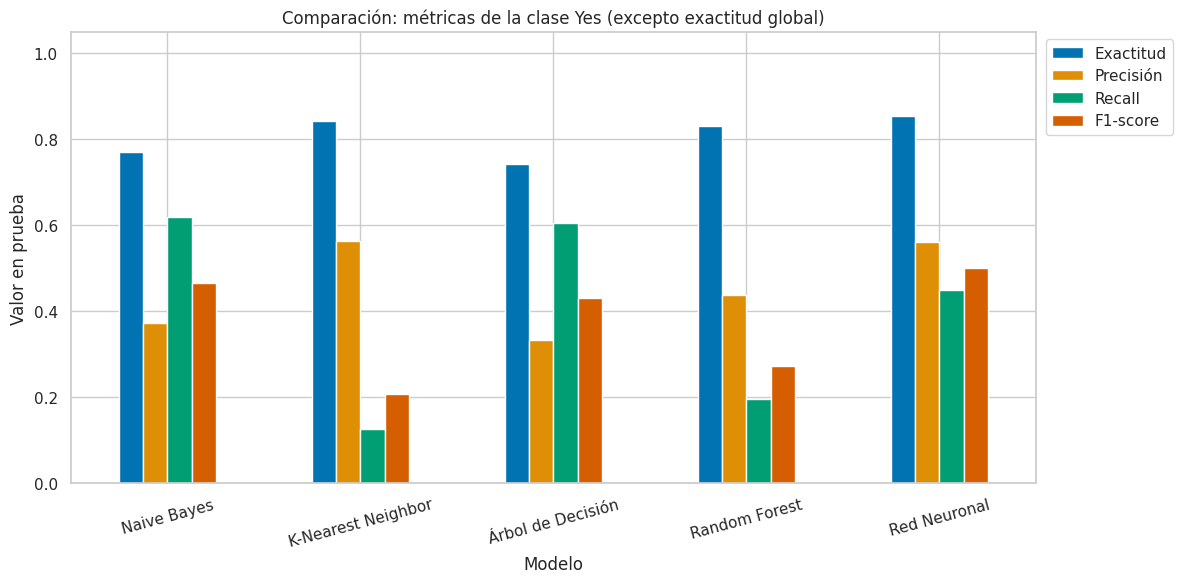

In [ ]:
# Tabla comparativa y gráfica de barras
resumen_modelos = resultados.copy()

comentarios = {
    'Red Neuronal': 'Detecta 32/71 bajas; 25 falsas alertas y 39 bajas omitidas.',
    'Naive Bayes': 'Detecta 44/71 bajas; 74 falsas alertas y 27 bajas omitidas.',
    'Árbol de Decisión': 'Detecta 43/71 bajas; 86 falsas alertas y 28 bajas omitidas.',
    'Random Forest': 'Detecta 14/71 bajas; 18 falsas alertas y 57 bajas omitidas.',
    'K-Nearest Neighbor': 'Detecta 9/71 bajas; 7 falsas alertas y 62 bajas omitidas.',
    'Baseline: siempre No': 'Exactitud alta sin resolver el problema. Cero deteccion.'
}
resumen_modelos['Comentario'] = resumen_modelos['Modelo'].map(comentarios)

pd.set_option('display.max_colwidth', None)

# Mostrar la tabla resumen
cols_mostrar = ['Modelo', 'Variables utilizadas', 'Exactitud', 'Precisión', 'Recall', 'F1-score', 'Interpretación breve']
display(Markdown('**Tabla 10: Comparación en los 441 registros de prueba**'))
tabla('10_comparacion_prueba', resumen_modelos[cols_mostrar])

# Gráfica de barras
df_plot = resumen_modelos[resumen_modelos['Modelo'] != 'Baseline: siempre No'].set_index('Modelo')
df_plot[['Exactitud', 'Precisión', 'Recall', 'F1-score']].plot(kind='bar', figsize=(12, 6))

plt.title('Comparación: métricas de la clase Yes (excepto exactitud global)')
plt.ylabel('Valor en prueba')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(['Exactitud', 'Precisión', 'Recall', 'F1-score'], loc='upper right', bbox_to_anchor=(1.15, 1))
plt.tight_layout()
figura('10_grafica_comparativa_metricas')

### Análisis

La red neuronal obtuvo el mayor F1 en esta prueba y el mayor ROC-AUC. Detectó 32 de las 71 bajas, con 25 falsas alertas; todavía dejó 39 sin detectar. Naive Bayes reconoció más bajas, 44, pero generó 74 falsas alertas. El árbol tuvo un comportamiento similar, con 43 bajas detectadas y 86 falsas alertas.

En el caso de KNN, la exactitud fue alta (~0.84), pero solamente encontró nueve bajas. La referencia que siempre responde `No` obtiene casi 0.84 de exactitud y cero recall y F1 para bajas. Lo que esto nos quiere decir es que una exactitud cercana al 84% puede obtenerse sin resolver el problema que nos interesa. Random Forest reconoció 14 bajas, por lo que su umbral de 0.5 resultó poco sensible a esta clase.

Se calculó **ROC-AUC** a partir de probabilidades y **AP** como resumen de la curva precision-recall. Estas curvas permiten revisar distintos umbrales. Las líneas de referencia corresponden a discriminación aleatoria en ROC y proporción de bajas en precision-recall.

**Tabla 11: Discriminación con probabilidades y promedio de precisión (AP)**

,Modelo,ROC-AUC,AP
1,Naive Bayes,0.7730,0.5182
2,K-Nearest Neighbor,0.6309,0.3242
3,Árbol de Decisión,0.7061,0.3577
4,Random Forest,0.7787,0.4342
5,Red Neuronal,0.8075,0.5814


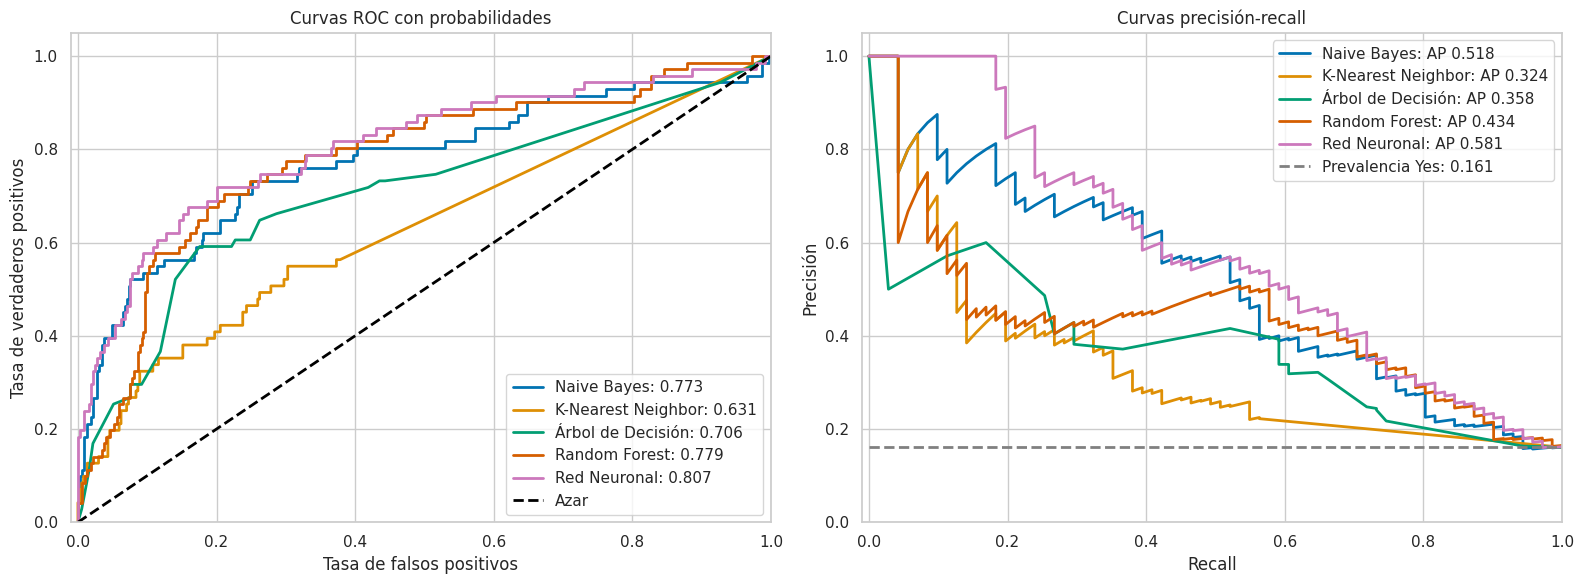

In [ ]:
# Tabla de ROC-AUC y AP
tabla_auc_ap = resumen_modelos[resumen_modelos['Modelo'] != 'Baseline: siempre No'][['Modelo', 'ROC-AUC', 'AP']].copy()
display(Markdown('**Tabla 11: Discriminación con probabilidades y promedio de precisión (AP)**'))
tabla('11_auc_ap', tabla_auc_ap)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#Curva ROC (Izquierda)
for nombre in modelos.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilidades[nombre])
    auc_val = roc_auc_score(y_test, probabilidades[nombre])
    axes[0].plot(fpr, tpr, lw=2, label=f'{nombre}: {auc_val:.3f}')

axes[0].plot([0, 1], [0, 1], color='black', lw=2, linestyle='--', label='Azar')
axes[0].set(xlim=[-0.01, 1.0], ylim=[0.0, 1.05], xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos', title='Curvas ROC con probabilidades')
axes[0].legend(loc="lower right")

# Curva Precision-Recall (Derecha)
prevalencia_yes = (y_test == 1).mean()

for nombre in modelos.keys():
    prec, rec, _ = precision_recall_curve(y_test, probabilidades[nombre])
    ap_val = average_precision_score(y_test, probabilidades[nombre])
    axes[1].plot(rec, prec, lw=2, label=f'{nombre}: AP {ap_val:.3f}')

axes[1].plot([0, 1], [prevalencia_yes, prevalencia_yes], color='gray', lw=2, linestyle='--', label=f'Prevalencia Yes: {prevalencia_yes:.3f}')
axes[1].set(xlim=[-0.01, 1.0], ylim=[0.0, 1.05], xlabel='Recall', ylabel='Precisión', title='Curvas precisión-recall')
axes[1].legend(loc="upper right")

plt.tight_layout()
figura('11_curvas_roc_pr')

## Parte 6. Explicabilidad e interpretabilidad
### 6.1. Variables que influyen en cada modelo
Para revisar qué variables tuvieron mayor influencia en los modelos se utilizó la importancia por permutación. Este método consiste en cambiar los valores de una columna en los datos de prueba y medir cuánto disminuye el ROC-AUC. Para cada modelo se hicieron cinco repeticiones. Si la caída es mayor, significa que el modelo dependió más de esa variable en esta prueba. Las barras de error muestran la variación entre las diferentes permutaciones y no representan un intervalo de confianza.

Se permutaron las columnas originales para mantener juntas las categorías que después se convierten en variables one-hot. Además, cuando dos variables están relacionadas, pueden repartirse la importancia entre ellas. Por otro lado, una importancia cercana a cero o negativa indica que la variable no tuvo una contribución constante en esta prueba. Estas gráficas permiten saber qué variables utiliza más el modelo, pero no demuestran que cambiar una condición laboral provoque una baja y tampoco se utilizan para volver a seleccionar las variables.

Las tablas muestran las 10 variables con mayor caída en ROC-AUC, mientras que las gráficas muestran solamente las 8 principales (Figura 10). `OverTime` ocupa el primer lugar en los cinco modelos: su caída de ROC-AUC fue de 0.048 en Naive Bayes, 0.044 en KNN, 0.111 en el árbol, 0.081 en Random Forest y 0.070 en la red neuronal. Es la única variable que se mantiene como una de las principales en todos los modelos y coincide con lo observado en la Parte 2, donde el 30.5% de los empleados con horas extra dejaron la empresa, frente al 10.4% de los que no hacían horas extra.

Después de `OverTime`, el orden de importancia cambia dependiendo del modelo. En Naive Bayes destacan `MaritalStatus` y `JobRole`; en KNN, `DailyRate` y `YearsAtCompany`; en el árbol, `JobLevel` y `StockOptionLevel`; en Random Forest, `EnvironmentSatisfaction` y `StockOptionLevel`; y en la red neuronal, `StockOptionLevel` (nivel de opciones de acciones) y `MonthlyIncome`. Algunas barras de error son relativamente grandes en comparación con la caída, como ocurre con `DailyRate` en KNN o con `Age` y `YearsAtCompany` en el árbol. Por esto, considerando que solo hay 71 bajas en los datos de prueba, el orden de las variables secundarias debe tomarse como una referencia y no como una diferencia definitiva. Las caídas también son relativamente pequeñas porque, al cambiar una variable, las demás todavía conservan parte de la información que utiliza el modelo.



,Variable,Caída ROC-AUC,Desviación,Caída > 2 desviaciones
18,OverTime,0.0475,0.0045,True
14,MaritalStatus,0.0155,0.0048,True
12,JobRole,0.0132,0.0078,False
15,MonthlyIncome,0.0109,0.0103,False
1,BusinessTravel,0.0108,0.0032,True
13,JobSatisfaction,0.0073,0.0019,True
11,JobLevel,0.0068,0.0071,False
17,NumCompaniesWorked,0.0051,0.0019,True
25,WorkLifeBalance,0.0047,0.0038,False
7,EnvironmentSatisfaction,0.0039,0.0027,False


,Variable,Caída ROC-AUC,Desviación,Caída > 2 desviaciones
18,OverTime,0.0440,0.0042,True
2,DailyRate,0.0289,0.0180,False
26,YearsAtCompany,0.0202,0.0050,True
10,JobInvolvement,0.0201,0.0136,False
13,JobSatisfaction,0.0134,0.0072,False
7,EnvironmentSatisfaction,0.0131,0.0114,False
5,Education,0.0118,0.0096,False
23,TotalWorkingYears,0.0115,0.0036,True
3,Department,0.0111,0.0138,False
0,Age,0.0111,0.0192,False


,Variable,Caída ROC-AUC,Desviación,Caída > 2 desviaciones
18,OverTime,0.1107,0.0093,True
11,JobLevel,0.0740,0.0176,True
22,StockOptionLevel,0.0451,0.0186,True
0,Age,0.0384,0.0229,False
26,YearsAtCompany,0.0329,0.0312,False
29,YearsWithCurrManager,0.0276,0.0109,True
19,PercentSalaryHike,0.0227,0.0121,False
21,RelationshipSatisfaction,0.0104,0.0020,True
15,MonthlyIncome,0.0038,0.0050,False
4,DistanceFromHome,0.0032,0.0051,False


,Variable,Caída ROC-AUC,Desviación,Caída > 2 desviaciones
18,OverTime,0.0807,0.0060,True
7,EnvironmentSatisfaction,0.0125,0.0013,True
22,StockOptionLevel,0.0098,0.0041,True
13,JobSatisfaction,0.0091,0.0022,True
10,JobInvolvement,0.0082,0.0040,True
15,MonthlyIncome,0.0059,0.0080,False
1,BusinessTravel,0.0059,0.0028,True
4,DistanceFromHome,0.0045,0.0051,False
2,DailyRate,0.0036,0.0036,False
0,Age,0.0035,0.0047,False


,Variable,Caída ROC-AUC,Desviación,Caída > 2 desviaciones
18,OverTime,0.0700,0.0081,True
22,StockOptionLevel,0.0291,0.0049,True
15,MonthlyIncome,0.0283,0.0146,False
13,JobSatisfaction,0.0261,0.0113,True
23,TotalWorkingYears,0.0254,0.0128,False
28,YearsSinceLastPromotion,0.0238,0.0078,True
1,BusinessTravel,0.0216,0.0076,True
4,DistanceFromHome,0.0206,0.0037,True
14,MaritalStatus,0.0196,0.0048,True
7,EnvironmentSatisfaction,0.0156,0.0103,False


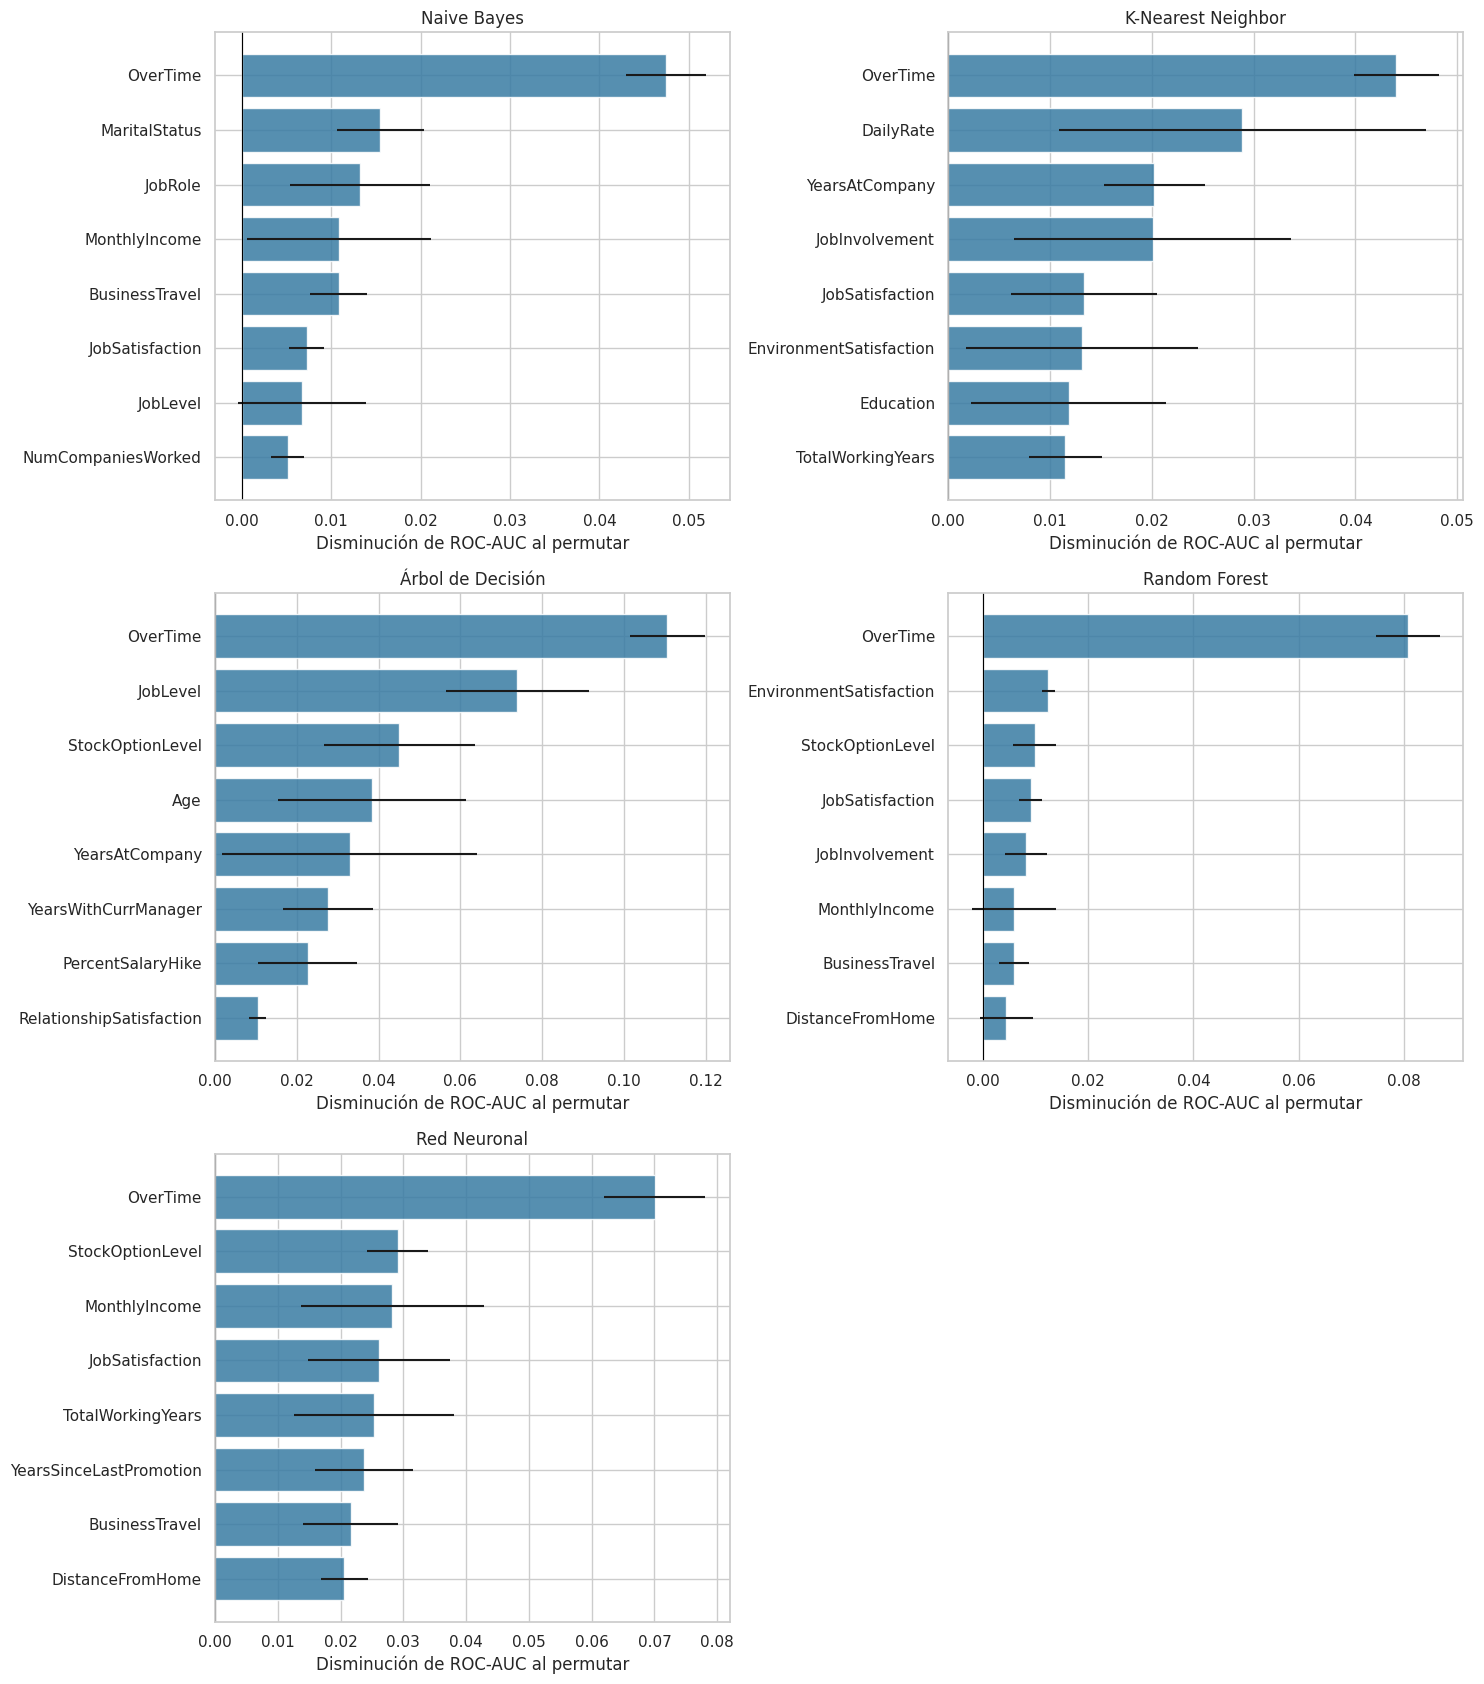

**Naive Bayes:** la permutación arroja como mayor contribución a OverTime, MaritalStatus, JobRole. Este orden corresponde al modelo y a los registros de esta prueba.

**K-Nearest Neighbor:** la permutación arroja como mayor contribución a OverTime, DailyRate, YearsAtCompany. Este orden corresponde al modelo y a los registros de esta prueba.

**Árbol de Decisión:** la permutación arroja como mayor contribución a OverTime, JobLevel, StockOptionLevel. Este orden corresponde al modelo y a los registros de esta prueba.

**Random Forest:** la permutación arroja como mayor contribución a OverTime, EnvironmentSatisfaction, StockOptionLevel. Este orden corresponde al modelo y a los registros de esta prueba.

**Red Neuronal:** la permutación arroja como mayor contribución a OverTime, StockOptionLevel, MonthlyIncome. Este orden corresponde al modelo y a los registros de esta prueba.

,Modelo,Caída ROC-AUC (OverTime),Desviación,Posición
0,Naive Bayes,0.0475,0.0045,1
1,K-Nearest Neighbor,0.0440,0.0042,1
2,Árbol de Decisión,0.1107,0.0093,1
3,Random Forest,0.0807,0.0060,1
4,Red Neuronal,0.0700,0.0081,1


In [ ]:
importancias_perm={}
fig,axes=plt.subplots(3,2,figsize=(15,17))
for ax,(nombre,clf) in zip(axes.flat,modelos.items()):
    perm=permutation_importance(clf,X_test,y_test,scoring='roc_auc',n_repeats=5,random_state=SEED,n_jobs=1)
    t=pd.DataFrame({'Variable':X.columns,'Caída ROC-AUC':perm.importances_mean,
                    'Desviación':perm.importances_std}).sort_values('Caída ROC-AUC',ascending=False)
    t['Caída > 2 desviaciones']=t['Caída ROC-AUC']>2*t['Desviación']   # criterio práctico, no prueba estadística
    importancias_perm[nombre]=t
    tabla('12_permutacion_'+nombre.replace(' ','_'),t.head(10))
    top=t.head(8).iloc[::-1]
    ax.barh(top['Variable'],top['Caída ROC-AUC'],xerr=top['Desviación'],color='#387ba3',alpha=.85)
    ax.axvline(0,color='black',linewidth=.8)
    ax.set(title=nombre,xlabel='Disminución de ROC-AUC al permutar')
axes.flat[-1].axis('off')
figura('12_importancia_cada_modelo')

for nombre,t in importancias_perm.items():
    positivas=t[t['Caída ROC-AUC']>0].head(3)
    display(Markdown(f'**{nombre}:** la permutación arroja como mayor contribución a '+', '.join(positivas['Variable'])+
                     '. Este orden corresponde al modelo y a los registros de esta prueba.'))

# Tabla resumen: OverTime en los cinco modelos
resumen_ot=pd.DataFrame([{'Modelo':n,
    'Caída ROC-AUC (OverTime)':float(t.set_index('Variable').loc['OverTime','Caída ROC-AUC']),
    'Desviación':float(t.set_index('Variable').loc['OverTime','Desviación']),
    'Posición':int(list(t['Variable']).index('OverTime')+1)} for n,t in importancias_perm.items()])
tabla('12b_overtime_resumen',resumen_ot)


### 6.2. Naive Bayes: probabilidades y explicacion de un caso
Para este análisis se obtuvieron las medias y varianzas que `GaussianNB` aprendió para cada clase. Se muestran diez variables que tienen diferencias grandes entre sus medias, junto con las probabilidades obtenidas para el primer registro de prueba. La tabla de contribuciones permite ver qué variables apoyan la predicción hacia `Yes` o hacia `No`: un valor positivo favorece `Yes`, mientras que uno negativo favorece `No`.

Las mayores diferencias entre las medias se encuentran principalmente en variables relacionadas con la experiencia y el nivel del empleado. Entre ellas están `Age` (−0.50), `TotalWorkingYears` (−0.50), `YearsInCurrentRole` (−0.47), `YearsWithCurrManager` (−0.46), `JobLevel` (−0.44), `MonthlyIncome` (−0.44) y `YearsAtCompany` (−0.44), en unidades estandarizadas. En todas ellas, los empleados que dejaron la empresa tienen valores más bajos. Como varias de estas variables están relacionadas entre sí, Naive Bayes las trata como si fueran independientes y suma su información para realizar la predicción.

El caso de prueba #0, que corresponde a la posición original 397, es un error del modelo. La clase real es `No`, pero Naive Bayes asigna una probabilidad P(Yes) = 0.9039, partiendo de un prior de entrenamiento de 0.1613. Las variables que más apoyan la predicción `Yes` son `OverTime` (+0.5473 en cada una de sus dos columnas), `Age` (+0.5281), `MaritalStatus_Single` (+0.4420), `TotalWorkingYears` (+0.3778) y `MonthlyIncome` (+0.3351). Por otro lado, `JobSatisfaction` aporta −0.3272, favoreciendo la clase `No`.

Además, `OverTime_No` y `OverTime_Yes` son columnas complementarias y aportan el mismo valor. Por esto, el modelo termina contando la información de `OverTime` dos veces, con una contribución aproximada de 1.09 en log-odds. Esto muestra una de las limitaciones de Naive Bayes: la independencia entre las variables es solo una aproximación.

Finalmente, una probabilidad de 0.90 en un caso que realmente pertenece a `No` muestra que el modelo puede ser demasiado confiado en algunas predicciones. Naive Bayes detectó 44 de las 71 bajas, obteniendo un recall de 0.6197, pero también generó 74 falsas alertas y tuvo una precisión de 0.3729. Por esto, sus probabilidades deberían revisarse mediante una calibración antes de considerar su uso fuera de este ejercicio.



In [ ]:
nb_pipe=modelos['Naive Bayes']; nb=nb_pipe.named_steps['modelo']
nb_names=nb_pipe.named_steps['preparar'].get_feature_names_out()
i_no=list(nb.classes_).index(0);i_yes=list(nb.classes_).index(1)
param_nb=pd.DataFrame({'Entrada':nb_names,'Media No':nb.theta_[i_no],'Media Yes':nb.theta_[i_yes],
    'Varianza No':nb.var_[i_no],'Varianza Yes':nb.var_[i_yes]})
param_nb['Diferencia de medias']=param_nb['Media Yes']-param_nb['Media No']
tabla('13_nb_parametros',param_nb.reindex(param_nb['Diferencia de medias'].abs().sort_values(ascending=False).index).head(10))
caso_pos=0
caso=X_test.iloc[[caso_pos]]
z=nb_pipe.named_steps['preparar'].transform(caso)[0]
log_no=-.5*(np.log(2*np.pi*nb.var_[i_no])+(z-nb.theta_[i_no])**2/nb.var_[i_no])
log_yes=-.5*(np.log(2*np.pi*nb.var_[i_yes])+(z-nb.theta_[i_yes])**2/nb.var_[i_yes])
contrib=pd.DataFrame({'Entrada':nb_names,'Aporte log Yes/No':log_yes-log_no})
contrib=contrib.reindex(contrib['Aporte log Yes/No'].abs().sort_values(ascending=False).index)
p_nb=nb_pipe.predict_proba(caso)[0]
tabla('13_nb_probabilidad_caso',pd.DataFrame({'Clase':['No','Yes'],'Probabilidad':[p_nb[i_no],p_nb[i_yes]],'Prior de entrenamiento':[nb.class_prior_[i_no],nb.class_prior_[i_yes]]}))
tabla('13_nb_contribuciones_caso',contrib.head(10))
log_odds=np.log(nb.class_prior_[i_yes]/nb.class_prior_[i_no])+(log_yes-log_no).sum()
print('Caso de prueba #0; clase real:',int(y_test.iloc[0]),'; predicción:',int(nb_pipe.predict(caso)[0]))
print('Log-odds reconstruido con prior + todos los aportes:',round(float(log_odds),4))
# --- nuevo ---
overtime_total=contrib.loc[contrib['Entrada'].str.contains('OverTime'),'Aporte log Yes/No'].sum()
print('Aporte total de OverTime (ambas columnas):',round(float(overtime_total),4))
print('P(Yes) reconstruida desde el log-odds:',round(float(1/(1+np.exp(-log_odds))),4),
      '| P(Yes) de predict_proba:',round(float(p_nb[i_yes]),4))

,Entrada,Media No,Media Yes,Varianza No,Varianza Yes,Diferencia de medias
0,num__Age,0.0808,-0.4202,1.0498,1.1505,-0.5010
16,num__TotalWorkingYears,0.0802,-0.4168,1.0980,0.9031,-0.4970
20,num__YearsInCurrentRole,0.0759,-0.3948,1.1124,0.8496,-0.4707
22,num__YearsWithCurrManager,0.0750,-0.3897,1.0934,0.9534,-0.4647
7,num__JobLevel,0.0713,-0.3706,1.1130,0.8689,-0.4419
9,num__MonthlyIncome,0.0710,-0.3689,1.1396,0.7317,-0.4399
19,num__YearsAtCompany,0.0707,-0.3675,1.1186,0.8425,-0.4382
15,num__StockOptionLevel,0.0635,-0.3299,1.0739,1.1062,-0.3933
6,num__JobInvolvement,0.0547,-0.2842,1.0221,1.4086,-0.3389
4,num__EnvironmentSatisfaction,0.0484,-0.2514,1.0625,1.2195,-0.2998


,Clase,Probabilidad,Prior de entrenamiento
0,No,0.0961,0.8387
1,Yes,0.9039,0.1613


,Entrada,Aporte log Yes/No
49,cat__OverTime_No,0.5473
50,cat__OverTime_Yes,0.5473
0,num__Age,0.5281
48,cat__MaritalStatus_Single,0.4420
16,num__TotalWorkingYears,0.3778
9,num__MonthlyIncome,0.3351
8,num__JobSatisfaction,-0.3272
15,num__StockOptionLevel,0.2840
45,cat__JobRole_Sales Representative,-0.2743
28,cat__Department_Sales,0.2627


Caso de prueba #0; clase real: 0 ; predicción: 1
Log-odds reconstruido con prior + todos los aportes: 2.2413
Aporte total de OverTime (ambas columnas): 1.0945
P(Yes) reconstruida desde el log-odds: 0.9039 | P(Yes) de predict_proba: 0.9039


### 6.3. KNN: vecinos y votacion
Se revisaron los vecinos del primer registro de prueba, utilizando únicamente registros del conjunto de entrenamiento. La tabla muestra la distancia después de aplicar el escalado y la transformación one-hot, la clase real de cada vecino y su peso en la votación. También se comparan algunas características como edad, ingreso, horas extra y antigüedad para entender mejor qué registros considera cercanos el modelo.

El registro #0 tiene 25 años, un ingreso de 4,487, hace horas extra y lleva 5 años en la empresa. Sus cinco vecinos pertenecen a la clase `No`, por lo que KNN obtiene P(Yes) = 0 y acierta la predicción. Los vecinos tienen entre 27 y 37 años, entre 4 y 6 años en la empresa e ingresos de 4,478 a 8,103. Además, cuatro de los cinco hacen horas extra. Esto significa que los registros se parecen considerando el conjunto de variables, y no por una sola característica. La distancia se calcula utilizando las 51 entradas del modelo, no solamente las cuatro variables que se muestran en la tabla.

Las distancias están entre 3.64 y 4.05, mientras que los pesos de votación van de 0.189 a 0.210, por lo que son bastante parecidos. Con 51 variables, la diferencia entre el vecino más cercano y el quinto es pequeña. Una distancia menor solamente indica que los registros son parecidos después de aplicar las transformaciones del modelo, pero no significa que tengan la misma causa de rotación.

Esto ayuda a explicar el desempeño de KNN en la Parte 5. El modelo detectó solamente 9 de las 71 bajas, obteniendo un recall de 0.1268. Para predecir `Yes`, la mayoría de los vecinos debe pertenecer a esa clase, algo que ocurre pocas veces porque las bajas representan solo el 16% de los empleados. Por esto, aunque obtuvo un F1 de 1.0000 en entrenamiento, en prueba bajó a 0.2069. Finalmente, `EmployeeNumber` no se utilizó como predictor porque solamente funciona como identificador del empleado.



**Registro a explicar (prueba #0):**

,OverTime,MonthlyIncome,Age,YearsAtCompany
397,Yes,4487,25,5


,Vecino,OverTime,MonthlyIncome,Age,YearsAtCompany,Distancia,Clase Yes (real),Peso de voto
0,1,Yes,6582,31,6,3.6375,0,0.2104
1,2,No,7428,37,5,3.7115,0,0.2062
2,3,Yes,4478,27,5,3.7645,0,0.2033
3,4,Yes,6583,31,5,4.0014,0,0.1912
4,5,Yes,8103,34,4,4.0496,0,0.1890


P(Yes) por voto ponderado: 0.0
P(Yes) de predict_proba: 0.0
Predicción: 0 ; clase real: 0


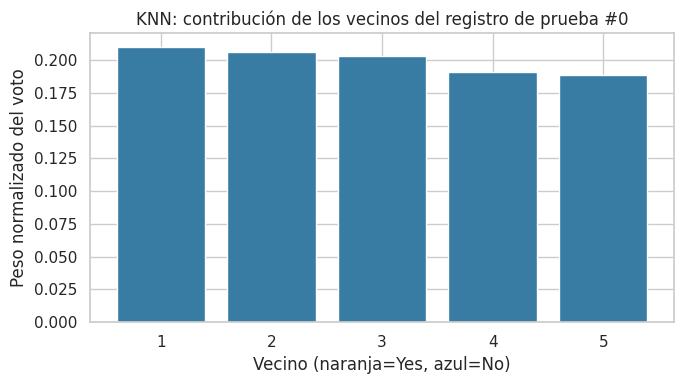

Distancia mínima y máxima: 3.6375 4.0496
Peso de voto mínimo y máximo: 0.189 0.2104
Vecinos con horas extra: 4 de 5


In [ ]:
knn_pipe=modelos['K-Nearest Neighbor']; knn=knn_pipe.named_steps['modelo']
z_caso=knn_pipe.named_steps['preparar'].transform(caso)
dist,idx=knn.kneighbors(z_caso)
dist,idx=dist[0],idx[0]
pesos=(dist==0).astype(float) if np.any(dist==0) else 1/np.maximum(dist,1e-12)
pesos=pesos/pesos.sum()
vecinos=X_train.iloc[idx][['OverTime','MonthlyIncome','Age','YearsAtCompany']].copy().reset_index(drop=True)
vecinos.insert(0,'Vecino',np.arange(1,len(idx)+1))
vecinos['Distancia']=dist
vecinos['Clase Yes (real)']=y_train.iloc[idx].to_numpy()
vecinos['Peso de voto']=pesos
display(Markdown('**Registro a explicar (prueba #0):**'))
display(caso[['OverTime','MonthlyIncome','Age','YearsAtCompany']])
tabla('14_knn_vecinos',vecinos)
print('P(Yes) por voto ponderado:',float(np.dot(pesos,y_train.iloc[idx].to_numpy())))
print('P(Yes) de predict_proba:',float(knn_pipe.predict_proba(caso)[0,1]))
print('Predicción:',int(knn_pipe.predict(caso)[0]),'; clase real:',int(y_test.iloc[0]))
plt.figure(figsize=(7,4))
plt.bar(vecinos['Vecino'].astype(str),vecinos['Peso de voto'],color=['#e07849' if c==1 else '#387ba3' for c in vecinos['Clase Yes (real)']])
plt.xlabel('Vecino (naranja=Yes, azul=No)');plt.ylabel('Peso normalizado del voto')
plt.title('KNN: contribución de los vecinos del registro de prueba #0')
figura('14_knn_votos')
# --- nuevo ---
print('Distancia mínima y máxima:',round(float(dist.min()),4),round(float(dist.max()),4))
print('Peso de voto mínimo y máximo:',round(float(pesos.min()),4),round(float(pesos.max()),4))
print('Vecinos con horas extra:',int((vecinos['OverTime']=='Yes').sum()),'de',len(vecinos))

### 6.4. Arbol de decision: reglas y recorrido
Se dibujó el árbol mostrando hasta la profundidad 3, aunque su profundidad real es 5. Las reglas completas se guardaron en `15_reglas_arbol.txt` y también se muestra el recorrido que sigue el primer caso de prueba. `samples` indica cuántos registros llegan a cada nodo, mientras que `value` considera los pesos de las clases debido a `class_weight='balanced'`. Por esto, los valores de `value` no coinciden directamente con `samples`. En las variables numéricas, los cortes mantienen sus unidades originales, mientras que en las variables one-hot un corte de 0.5 sirve para separar entre la categoría ausente y presente.

La raíz del árbol divide usando `YearsAtCompany <= 2.5`. Los empleados con 2.5 años o menos en la empresa (238 de los 1,029 registros de entrenamiento) pasan a una rama donde predomina `Yes`. Los que tienen más antigüedad pasan a una división por `OverTime`: quienes hacen horas extra (226 registros) llegan a un nodo clasificado como `Yes`, mientras que quienes no hacen horas extra (565) llegan a uno clasificado como `No`. De esta forma, el árbol resume dos perfiles que tienen mayor riesgo de baja: tener poca antigüedad, o tener más antigüedad y hacer horas extra.

Aunque la raíz utiliza `YearsAtCompany`, la importancia por permutación de la sección 6.1 coloca a `OverTime` en primer lugar. Esto no es una contradicción, ya que las dos medidas analizan cosas diferentes. El primer corte indica qué variable permite separar mejor las clases en ese punto del entrenamiento, mientras que la permutación mide cuánto disminuye el desempeño en los datos de prueba cuando se altera una variable.

Para el caso #0, el recorrido comienza con `YearsAtCompany` = 5, por lo que cumple `> 2.5`. Después, `OverTime_No` = 0 cumple `≤ 0.5`, lo que indica que el empleado sí hace horas extra. El recorrido continúa con `JobLevel` = 2 (`> 1.5`), `StockOptionLevel` = 0 (`≤ 0.5`) y `YearsWithCurrManager` = 3 (`> 2.5`). Finalmente, el árbol llega a una hoja que predice `Yes`, aunque la clase real es `No`. Por lo tanto, comete el mismo falso positivo que Naive Bayes. Este recorrido permite ver las condiciones que llevaron al modelo a tomar esa decisión.

En conjunto, el árbol detectó 43 de las 71 bajas y generó 86 falsas alertas, obteniendo una precisión de 0.3333.



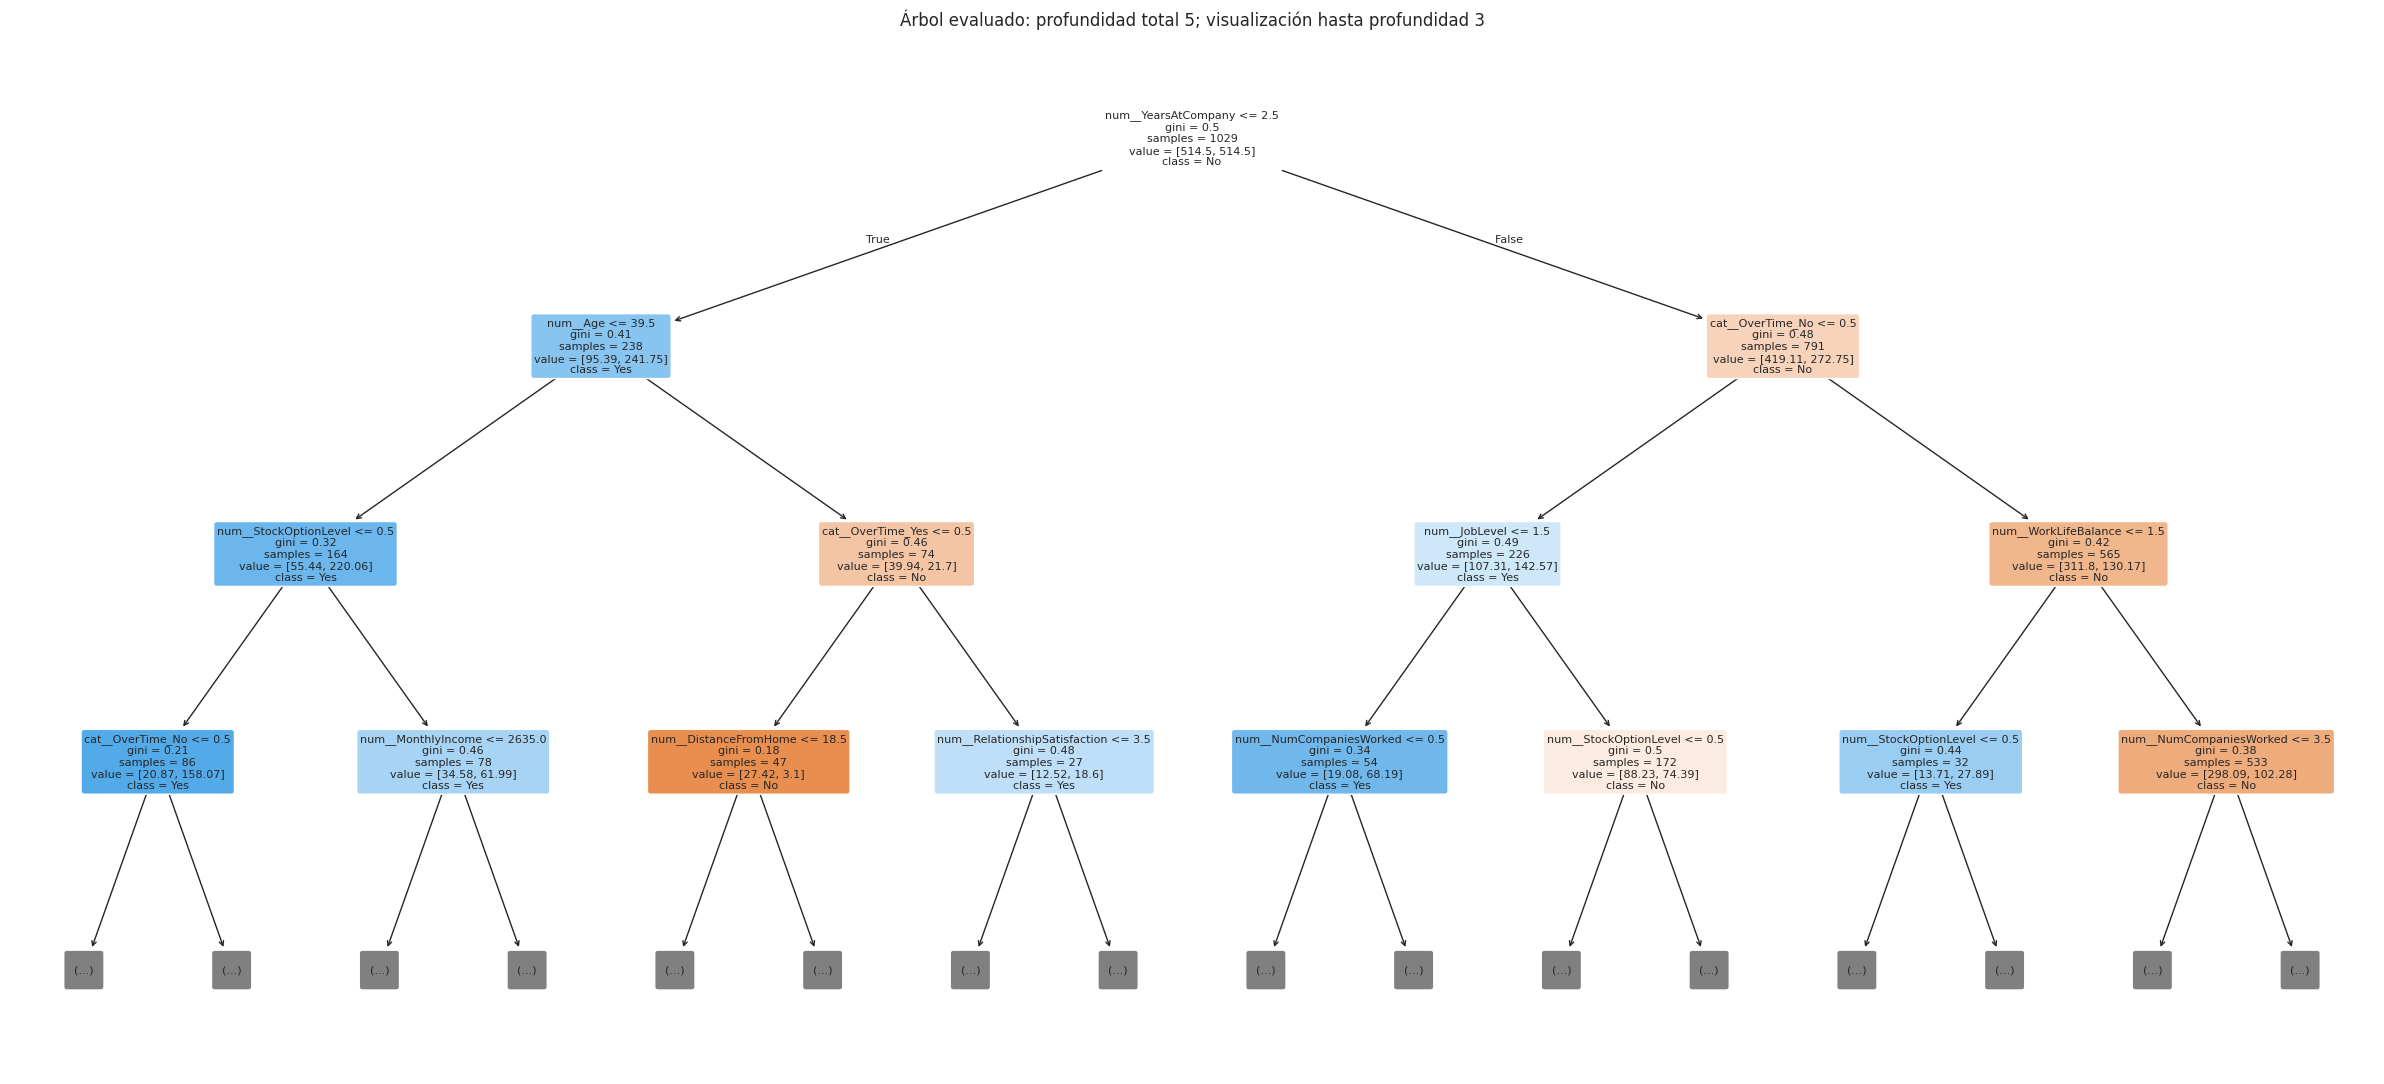

|--- num__YearsAtCompany <= 2.50
|   |--- num__Age <= 39.50
|   |   |--- num__StockOptionLevel <= 0.50
|   |   |   |--- cat__OverTime_No <= 0.50
|   |   |   |   |--- cat__EducationField_Life Sciences <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- cat__EducationField_Life Sciences >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- cat__OverTime_No >  0.50
|   |   |   |   |--- num__Age <= 32.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- num__Age >  32.50
|   |   |   |   |   |--- class: 0
|   |   |--- num__StockOptionLevel >  0.50
|   |   |   |--- num__MonthlyIncome <= 2635.00
|   |   |   |   |--- cat__JobRole_Research Scientist <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- cat__JobRole_Research Scientist >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- num__MonthlyIncome >  2635.00
|   |   |   |   |--- num__PercentSalaryHike <= 14.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- num__PercentSalaryHike >  14.50
|   | 

,Nodo,Variable,Valor del caso,Umbral,Rama
0,0,num__YearsAtCompany,5.0000,2.5000,>
1,24,cat__OverTime_No,0.0000,0.5000,<=
2,25,num__JobLevel,2.0000,1.5000,>
3,31,num__StockOptionLevel,0.0000,0.5000,<=
4,32,num__YearsWithCurrManager,3.0000,2.5000,>


Hoja final: 34 | samples: 50 | value (ponderado): [[0.29, 0.71]]
Predicción de este árbol: 1 ; clase real: 0


In [ ]:
arbol_pipe=modelos['Árbol de Decisión'];arbol=arbol_pipe.named_steps['modelo']
arbol_names=arbol_pipe.named_steps['preparar'].get_feature_names_out()
plt.figure(figsize=(24,11))
plot_tree(arbol,feature_names=arbol_names,class_names=['No','Yes'],filled=True,rounded=True,max_depth=3,fontsize=8,precision=2)
plt.title(f'Árbol evaluado: profundidad total {arbol.get_depth()}; visualización hasta profundidad 3')
figura('15_arbol_decision')
reglas_arbol=export_text(arbol,feature_names=list(arbol_names),decimals=2)
(OUT/'15_reglas_arbol.txt').write_text(reglas_arbol,encoding='utf-8')
print(reglas_arbol[:6000])
z_arbol=arbol_pipe.named_steps['preparar'].transform(caso)
nodos=arbol.decision_path(z_arbol).indices
ruta=[]
for nodo in nodos:
    if arbol.tree_.children_left[nodo]==arbol.tree_.children_right[nodo]:continue
    f=arbol.tree_.feature[nodo];v=float(z_arbol[0,f]);umbral=float(arbol.tree_.threshold[nodo])
    ruta.append({'Nodo':int(nodo),'Variable':arbol_names[f],'Valor del caso':v,'Umbral':umbral,'Rama':'<=' if v<=umbral else '>'})
tabla('15_ruta_arbol_caso',pd.DataFrame(ruta))
hoja=int(nodos[-1])
print('Hoja final:',hoja,'| samples:',int(arbol.tree_.n_node_samples[hoja]),
      '| value (ponderado):',arbol.tree_.value[hoja].round(2).tolist())
print('Predicción de este árbol:',int(arbol_pipe.predict(caso)[0]),'; clase real:',int(y_test.iloc[0]))

### 6.5. Random Forest: importancia de las variables
Random Forest combina las predicciones de 200 árboles. Para analizar qué variables utiliza más, se obtuvo la importancia por reducción de impureza y se sumaron las categorías de one-hot para volver a las variables originales. Después, estos resultados se compararon con la importancia por permutación .

Las dos medidas muestran resultados diferentes. Por reducción de impureza destacan `MonthlyIncome` (0.0838), `OverTime` (0.0720), `Age` (0.0655) y `TotalWorkingYears` (0.0534). También aparecen entre las primeras `DailyRate` (0.0471), `MonthlyRate` (0.0398) y `HourlyRate` (0.0392). En cambio, por permutación, `OverTime` es claramente la primera (0.0807), seguida de `EnvironmentSatisfaction`, `StockOptionLevel`, `JobSatisfaction` y `JobInvolvement`. `MonthlyIncome` baja al sexto lugar y tiene una barra de error grande. `Age` y `DailyRate` quedan entre las últimas posiciones, con caídas muy pequeñas, mientras que `MonthlyRate` y `HourlyRate` ya no aparecen entre las diez principales.

Esta diferencia muestra que la reducción de impureza puede dar más importancia a las variables continuas que tienen muchos posibles puntos de corte. Además, esta medida se calcula con los datos de entrenamiento, donde el bosque está sobreajustado, ya que obtuvo un F1 de 0.9790 en entrenamiento frente a 0.2718 en prueba. Por esto, para este análisis se considera más confiable la importancia por permutación. Aun así, hay una coincidencia importante: `OverTime` es la única variable que se mantiene entre las principales en ambas medidas. También hay que recordar que una importancia alta no indica por sí sola si una variable aumenta o disminuye la probabilidad de baja.

En esta prueba, Random Forest obtuvo un ROC-AUC de 0.7777, pero con un umbral de 0.5 solamente detectó 14 de las 71 bajas, obteniendo un recall de 0.1972. Para el caso #0, el modelo asigna P(Yes) = 0.3904 y predice permanencia (`No`), por lo que acierta. Sin embargo, su baja sensibilidad muestra que sería interesante analizar otros umbrales en una evaluación posterior, utilizando validación y manteniendo los datos de prueba separados.



,Variable,Importancia interna
15,MonthlyIncome,0.0838
18,OverTime,0.0720
0,Age,0.0655
23,TotalWorkingYears,0.0534
26,YearsAtCompany,0.0472
2,DailyRate,0.0471
12,JobRole,0.0466
29,YearsWithCurrManager,0.0464
22,StockOptionLevel,0.0418
16,MonthlyRate,0.0398


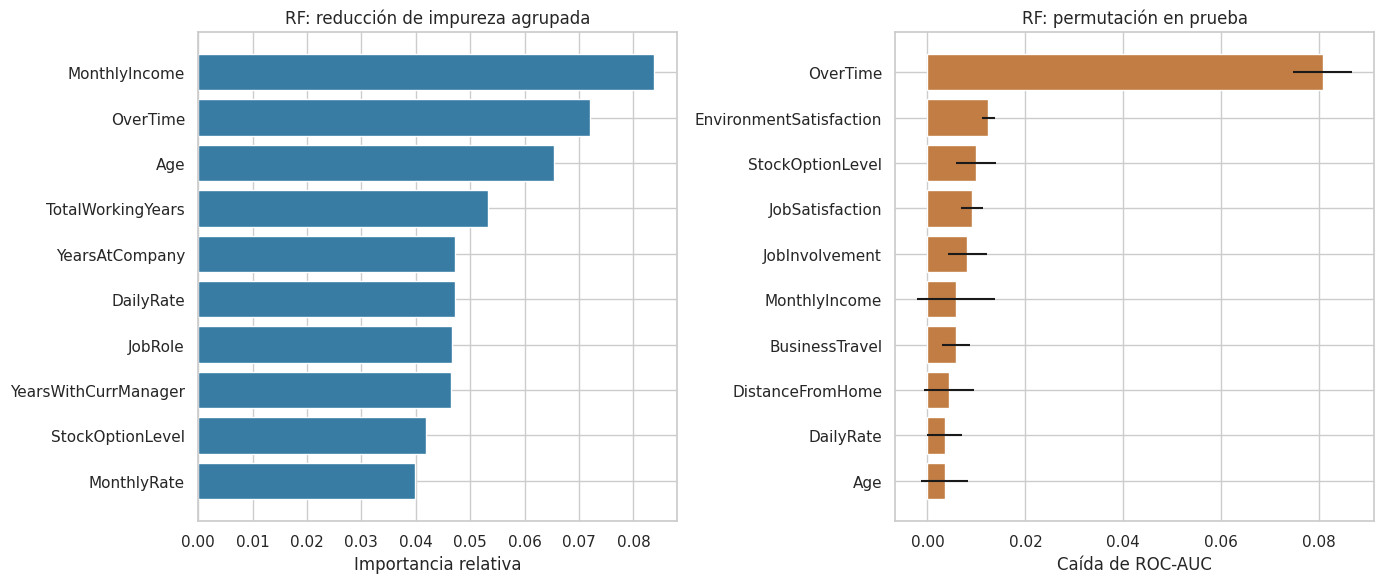

,Variable,Importancia interna,Rango impureza,Caída ROC-AUC,Rango permutación
0,MonthlyIncome,0.0838,1,0.0059,6
1,OverTime,0.0720,2,0.0807,1
2,Age,0.0655,3,0.0035,10
3,TotalWorkingYears,0.0534,4,-0.0072,30
4,YearsAtCompany,0.0472,5,-0.0065,29
5,DailyRate,0.0471,6,0.0036,9
6,JobRole,0.0466,7,0.0005,17
7,YearsWithCurrManager,0.0464,8,-0.0051,28
8,StockOptionLevel,0.0418,9,0.0098,3
9,MonthlyRate,0.0398,10,-0.0010,24


In [ ]:
rf_pipe=modelos['Random Forest'];rf=rf_pipe.named_steps['modelo'];prep_rf=rf_pipe.named_steps['preparar']
ohe=prep_rf.named_transformers_['cat'].named_steps['onehot']
originales=NUM.copy()
for c,categorias in zip(CAT,ohe.categories_):originales.extend([c]*len(categorias))
assert len(originales)==len(rf.feature_importances_)
imp_rf=pd.DataFrame({'Variable':originales,'Importancia interna':rf.feature_importances_}).groupby('Variable',as_index=False).sum().sort_values('Importancia interna',ascending=False)
tabla('16_rf_importancia_agrupada',imp_rf)
fig,axes=plt.subplots(1,2,figsize=(14,6))
t=imp_rf.head(10).iloc[::-1]
axes[0].barh(t['Variable'],t['Importancia interna'],color='#387ba3')
axes[0].set(title='RF: reducción de impureza agrupada',xlabel='Importancia relativa')
t=importancias_perm['Random Forest'].head(10).iloc[::-1]
axes[1].barh(t['Variable'],t['Caída ROC-AUC'],xerr=t['Desviación'],color='#c17d43')
axes[1].set(title='RF: permutación en prueba',xlabel='Caída de ROC-AUC')
figura('16_rf_dos_importancias')
rangos_imp=imp_rf.reset_index(drop=True);rangos_imp['Rango impureza']=rangos_imp.index+1
rangos_perm=importancias_perm['Random Forest'].reset_index(drop=True);rangos_perm['Rango permutación']=rangos_perm.index+1
comp_rf=rangos_imp.merge(rangos_perm[['Variable','Caída ROC-AUC','Rango permutación']],on='Variable')
tabla('16b_rf_rangos_comparados',comp_rf.sort_values('Rango impureza').head(12))

### 6.6. Red neuronal: capas, pesos y entrenamiento

Se obtuvieron los tamaños de las capas, los pesos y los sesgos de la red entrenada. La arquitectura es 51 → 20 → 10 → 1, con dos capas ocultas que utilizan ReLU y una neurona de salida logística que calcula $P(\text{Yes})$. La red tiene 1,230 pesos y 31 sesgos, además de regularización L2 ($\alpha = 1$) y el optimizador Adam. El diagrama muestra todos los nodos y conexiones, usando azul para los pesos positivos, naranja para los negativos y un mayor grosor para los pesos de mayor magnitud. Sin embargo, con 1,230 conexiones es difícil de leer, por lo que resulta más útil observar el mapa de calor de los pesos de la primera capa y la curva de pérdida.

El entrenamiento terminó en 379 iteraciones, con una pérdida final de 0.1712, sin alcanzar `max_iter`. Esta pérdida incluye la regularización y corresponde a los datos de entrenamiento, por lo que una disminución de la pérdida no significa necesariamente que la red tendrá el mismo desempeño con datos nuevos. Esto se observa en el F1, que fue de 0.9304 en entrenamiento y bajó a 0.5000 en prueba. Por lo tanto, existe sobreajuste, aunque la red neuronal fue el modelo con mejor desempeño en los datos de prueba. En el mapa de calor se observan pesos positivos y negativos distribuidos entre las 20 neuronas de la primera capa. No hay una sola entrada que domine, y un peso aislado tampoco permite determinar la importancia de una variable, ya que la predicción depende de las capas siguientes.

Para analizar la influencia de las variables se utilizó la importancia por permutación de la Figura 10. Las variables que más destacan en la red son `OverTime`, con una caída de 0.0700, `StockOptionLevel`, `MonthlyIncome` y `JobSatisfaction`. De estas, `OverTime` es la más importante y también fue la variable que se mantuvo como principal en los demás modelos.

La tabla final compara los cinco modelos utilizando el mismo registro #0, cuya clase real es `No`. Naive Bayes (P(Yes) = 0.9039) y el árbol de decisión generan una falsa alerta. En cambio, KNN (P(Yes) = 0), Random Forest (P(Yes) = 0.3904) y la red neuronal (P(Yes) = 0.1980) predicen permanencia y aciertan. Esto muestra que modelos con diferente desempeño general pueden dar respuestas distintas para un mismo registro. También se puede observar que una probabilidad alta, como la de Naive Bayes, no garantiza que la predicción sea correcta. Sin embargo, un solo caso no permite comparar cuál modelo es mejor; solamente sirve para mostrar cómo se comporta cada uno ante el mismo empleado.



,Conexión,Entradas,Salidas,Pesos,Sesgos,Media |peso|
0,Capa 0 → 1,51,20,1020,20,0.0712
1,Capa 1 → 2,20,10,200,10,0.1823
2,Capa 2 → 3,10,1,10,1,0.7823


Arquitectura exacta: 51 → 20 → 10 → 1
Activación oculta: relu | Salida: logistic
Iteraciones: 379 | Pérdida final: 0.17119182126311921


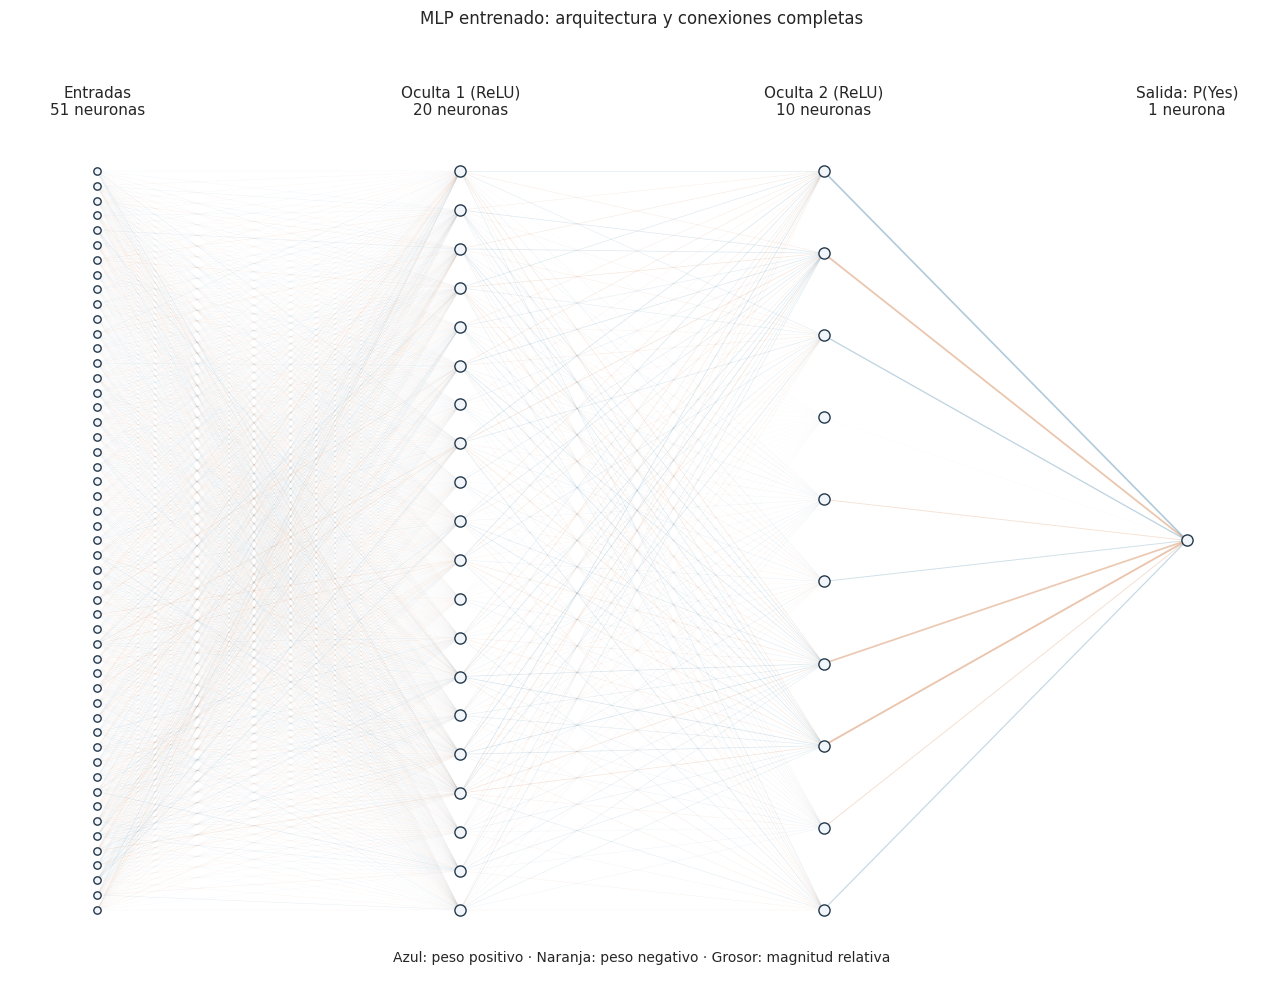

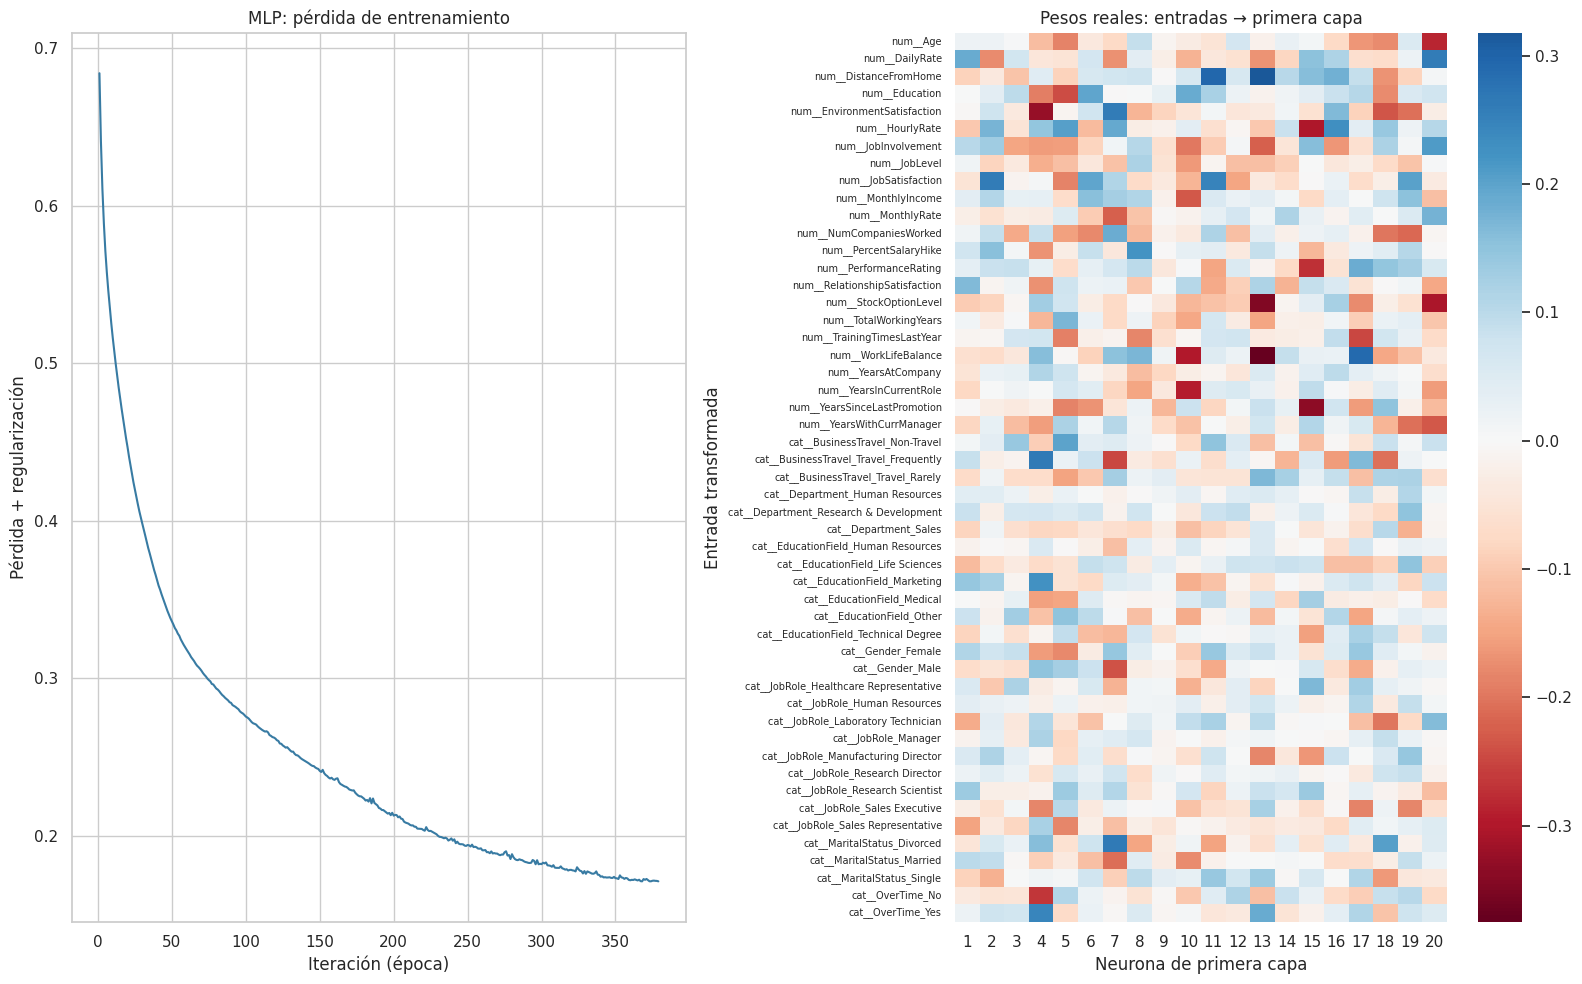

In [ ]:
mlp_pipe=modelos['Red Neuronal'];mlp=mlp_pipe.named_steps['modelo']
mlp_names=mlp_pipe.named_steps['preparar'].get_feature_names_out()
tamanos=[mlp.coefs_[0].shape[0]]+[w.shape[1] for w in mlp.coefs_]
capas=pd.DataFrame([{'Conexión':f'Capa {i} → {i+1}','Entradas':w.shape[0],'Salidas':w.shape[1],
    'Pesos':w.size,'Sesgos':len(b),'Media |peso|':float(np.abs(w).mean())} for i,(w,b) in enumerate(zip(mlp.coefs_,mlp.intercepts_))])
tabla('17_mlp_capas_pesos',capas)
print('Arquitectura exacta:', ' → '.join(map(str,tamanos)))
print('Activación oculta:',mlp.activation,'| Salida:',mlp.out_activation_)
print('Iteraciones:',mlp.n_iter_,'| Pérdida final:',mlp.loss_)
if mlp.n_iter_>=mlp.max_iter:print('Se alcanzó max_iter: revisar convergencia antes de recomendar.')
fig,ax=plt.subplots(figsize=(13,10))
xpos=np.linspace(0,1,len(tamanos))
ypos=[np.linspace(.04,.96,n) if n>1 else np.array([.5]) for n in tamanos]
maxw=max(float(np.abs(w).max()) for w in mlp.coefs_)
for layer,w in enumerate(mlp.coefs_):
    for i in range(w.shape[0]):
        for j in range(w.shape[1]):
            mag=abs(float(w[i,j]))/maxw
            ax.plot([xpos[layer],xpos[layer+1]],[ypos[layer][i],ypos[layer+1][j]],
                color='#387ba3' if w[i,j]>=0 else '#cf773f',linewidth=.12+1.2*mag,alpha=.08+.35*mag,zorder=1)
for k,(x,ys) in enumerate(zip(xpos,ypos)):
    ax.scatter(np.repeat(x,len(ys)),ys,s=28 if k==0 else 65,color='#f2f5fa',edgecolors='#24394c',zorder=2)
    label='Entradas' if k==0 else 'Salida: P(Yes)' if k==len(tamanos)-1 else f'Oculta {k} (ReLU)'
    ax.text(x,1.03,f'{label}\n{tamanos[k]} {"neurona" if tamanos[k]==1 else "neuronas"}',ha='center',fontsize=11)
ax.text(.5,-.025,'Azul: peso positivo · Naranja: peso negativo · Grosor: magnitud relativa',ha='center',fontsize=10)
ax.set(xlim=(-.08,1.08),ylim=(-.04,1.10));ax.axis('off')
ax.set_title('MLP entrenado: arquitectura y conexiones completas',pad=25)
figura('17_mlp_arquitectura_exacta')
fig,axes=plt.subplots(1,2,figsize=(16,10))
axes[0].plot(np.arange(1,len(mlp.loss_curve_)+1),mlp.loss_curve_,color='#387ba3')
axes[0].set(title='MLP: pérdida de entrenamiento',xlabel='Iteración (época)',ylabel='Pérdida + regularización')
sns.heatmap(mlp.coefs_[0],cmap='RdBu',center=0,ax=axes[1],yticklabels=mlp_names,xticklabels=np.arange(1,tamanos[1]+1))
axes[1].tick_params(axis='y',labelsize=7)
axes[1].set(title='Pesos reales: entradas → primera capa',xlabel='Neurona de primera capa',ylabel='Entrada transformada')
figura('17_mlp_perdida_y_pesos')

In [ ]:
caso_modelos=pd.DataFrame({
    'Modelo':list(modelos),
    'P(Yes)':[float(np.asarray(probabilidades[n])[caso_pos]) for n in modelos],
    'Predicción':[int(np.asarray(predicciones[n])[caso_pos]) for n in modelos],
    'Clase real':int(y_test.iloc[caso_pos])})
caso_modelos['¿Acierta?']=np.where(caso_modelos['Predicción']==caso_modelos['Clase real'],'Sí','No')
tabla('17b_caso0_cinco_modelos',caso_modelos)

,Modelo,P(Yes),Predicción,Clase real,¿Acierta?
0,Naive Bayes,0.9039,1,0,No
1,K-Nearest Neighbor,0.0000,0,0,Sí
2,Árbol de Decisión,0.7098,1,0,No
3,Random Forest,0.3904,0,0,Sí
4,Red Neuronal,0.1980,0,0,Sí


### 6.7. Revision de resultados por genero
Por último, se revisó el modelo seleccionado mediante validación cruzada, que en este caso fue la red neuronal, separando los resultados por género. Para cada grupo se muestra su tamaño, las bajas reales, las bajas detectadas, las falsas alertas, la precisión, el recall y el F1. Cuando alguna métrica no puede calcularse, se conserva como `NaN`. `Gender` sí forma parte de las variables de entrada del modelo, por lo que esta revisión analiza directamente un modelo que utiliza esta información.

La tasa de bajas es parecida entre ambos grupos: 15.4% en mujeres y 16.5% en hombres. En el grupo Female se detectaron 13 de 26 bajas, con un recall de 0.5000, mientras que en Male se detectaron 19 de 45, con un recall de 0.4222. La tasa de falsos positivos fue de 0.063 para mujeres y 0.071 para hombres. Aunque existe una diferencia en el recall, esta representa solamente entre dos y cuatro empleados. Por el tamaño de los grupos, estos resultados no son suficientes para concluir que el modelo discrimine por género, pero tampoco permiten asegurar que esté libre de posibles sesgos.

Para hacer una revisión más completa sería necesario analizar otras variables sensibles o que puedan estar relacionadas con ellas, como `Age` y `MaritalStatus`, esta última entre las variables más importantes de Naive Bayes. También sería útil comparar el desempeño del modelo con `Gender` y sin `Gender`. Quitar directamente una variable sensible no significa que desaparezca su posible influencia, ya que otras variables pueden estar relacionadas con ella. Finalmente, también se debe revisar que las variables utilizadas por el modelo sean datos que realmente estén disponibles antes de que ocurra una baja.


In [ ]:
auditoria=[]
p_sel=predicciones[seleccion_cv]
for grupo in sorted(X_test['Gender'].unique()):
    mask=X_test['Gender'].eq(grupo).to_numpy()
    yt=y_test.to_numpy()[mask];yp=p_sel[mask]
    tn,fp,fn,tp=confusion_matrix(yt,yp,labels=[0,1]).ravel()
    auditoria.append({'Gender':grupo,'n':len(yt),'Bajas reales':int(yt.sum()),
        'Tasa de bajas':float(yt.mean()),'Bajas detectadas':int(tp),'Falsas alertas':int(fp),
        'Precisión':float(tp/(tp+fp)) if tp+fp else np.nan,
        'Recall':float(tp/(tp+fn)) if tp+fn else np.nan,
        'F1':float(2*tp/(2*tp+fp+fn)) if 2*tp+fp+fn else np.nan,
        'Tasa falsos positivos':float(fp/(fp+tn)) if fp+tn else np.nan})
tabla('18_auditoria_genero',pd.DataFrame(auditoria))

,Gender,n,Bajas reales,Tasa de bajas,Bajas detectadas,Falsas alertas,Precisión,Recall,F1,Tasa falsos positivos
0,Female,169,26,0.1538,13,9,0.5909,0.5000,0.5417,0.0629
1,Male,272,45,0.1654,19,16,0.5429,0.4222,0.4750,0.0705


## Parte 7. Preguntas de validación
A partir de las salidas anteriores se responden las seis preguntas de la practica. Se indica tanto el resultado observado en prueba como la seleccion que se hizo mediante validacion cruzada, para explicar de donde sale la recomendacion.

1. ¿Cual fue la variable objetivo y por que es relevante para el negocio?

    La variable objetivo utilizada fue `Attrition` (`Yes = 1`, `No = 0`), la cual indica si un empleado dejó la empresa o si continúa trabajando en ella. Esta variable es importante porque la salida de un empleado puede generar diferentes gastos para la empresa, como la contratación y capacitación de una nueva persona. Además, también se puede perder experiencia y conocimiento que el trabajador adquirió durante el tiempo que estuvo en la organización. Por esta razón, contar con un modelo que permita identificar a los empleados con mayor riesgo de dejar la empresa podría ayudar a tomar medidas para intentar reducir estas bajas y priorizar acciones de retención.

    El conjunto de datos contiene 1,470 empleados, de los cuales 237 dejaron la empresa, lo que representa aproximadamente el 16.1%. Esto significa que la mayoría de los empleados permanecieron en su puesto, por lo que existe una diferencia importante entre las dos clases. Debido a esto, no es suficiente evaluar el modelo únicamente con la exactitud (`accuracy`). Por ejemplo, un modelo que siempre prediga `No` tendría una exactitud del 83.9%, pero no sería capaz de detectar ninguna de las bajas reales. Por lo tanto, también es necesario utilizar otras métricas que permitan conocer qué tan bien el modelo identifica a los empleados que dejaron la empresa.

    Además, en una aplicación real sería necesario definir desde qué momento se toman los datos y durante qué periodo se quiere predecir la posible baja. Esto permitiría saber si las variables utilizadas por el modelo realmente estarían disponibles antes de que el empleado deje la empresa.

        


2. ¿Que variables se consideraron mas importantes despues del EDA?

    Durante el **EDA (análisis exploratorio de datos)** se encontraron algunas diferencias importantes entre los empleados que dejaron la empresa y los que permanecieron. La variable que más destacó fue `OverTime`, ya que el 30.5% de los empleados que hacían horas extra dejaron la empresa, mientras que entre los que no hacían horas extra la tasa fue de 10.4%. También destacó `JobRole`, donde los `Sales Representative` tuvieron un 39.8% de bajas, aunque este resultado debe tomarse con cuidado porque solo había 83 empleados en ese puesto. En `Department`, el área de `Sales` presentó un 20.6% de bajas, frente al 13.8% de `Research & Development`.

    También se compararon `MonthlyIncome` y `YearsAtCompany`. Los empleados que dejaron la empresa tenían un ingreso mensual promedio de 4,787 y 5.13 años en la compañía, mientras que los que permanecieron tenían un ingreso promedio de 6,833 y 7.37 años. Estas diferencias permiten observar algunos patrones en los datos, pero no significan que una variable sea necesariamente la causa de que un empleado deje la empresa.

    Después del EDA, al entrenar los modelos se utilizó la importancia por permutación para analizar qué variables eran más utilizadas por cada modelo. En la red neuronal destacaron `OverTime`, `StockOptionLevel`, `MonthlyIncome`, `JobSatisfaction` y `TotalWorkingYears`. Sin embargo, la importancia de las demás variables cambió dependiendo del modelo. `OverTime` fue la única variable que se mantuvo como la más importante en los cinco modelos, por lo que fue el resultado más constante. Finalmente, se eliminaron `EmployeeNumber` porque solo funciona como identificador, y `EmployeeCount`, `StandardHours` y `Over18` porque tenían el mismo valor para todos los empleados.

    Es importante diferenciar ambos análisis: el EDA permite observar diferencias y patrones directamente en los datos, mientras que la importancia por permutación muestra cuánto cambia el desempeño del modelo cuando se modifica una variable. Ninguno de los dos análisis demuestra por sí solo que una variable sea la causa de la rotación de empleados.



3. ¿Que modelo obtuvo el mejor desempeño y con que metrica se justifica?

    El mejor desempeño lo obtuvo la **Red Neuronal**, principalmente por su valor de **F1 = 0.5000 para la clase `Yes`**. Esta métrica es importante porque toma en cuenta tanto las bajas que el modelo logra detectar como las falsas alertas, por lo que resulta adecuada debido al desbalance entre las clases. Además, obtuvo una **precisión de 0.5614**, un **recall de 0.4507**, una **exactitud de 0.8549**, un **ROC-AUC de 0.8075** y un **AP de 0.5814**. De los cinco modelos, tuvo los valores más altos de F1, ROC-AUC y AP.

    La exactitud debe interpretarse con cuidado, ya que el baseline que siempre predice `No` alcanza 0.8390. Esto significa que, aunque la red neuronal obtuvo 0.8549, la diferencia es de solo 1.6 puntos porcentuales. Además, KNN alcanzó una exactitud de 0.8435, pero solamente detectó 9 de las 71 bajas. Por esta razón, la elección del modelo no se hizo tomando la exactitud como criterio principal, sino considerando principalmente el F1 y apoyándose en ROC-AUC y AP.

    En los datos de prueba, la red neuronal detectó 32 de las 71 bajas y generó 25 falsas alertas. Naive Bayes y el árbol de decisión tuvieron un recall mayor, de aproximadamente 0.62 y 0.61, respectivamente, pero con una menor precisión. Esto significa que podrían ser una opción si para la empresa fuera mucho más importante detectar la mayor cantidad posible de bajas, aunque eso implique realizar más revisiones innecesarias. Por otro lado, Random Forest obtuvo un ROC-AUC de 0.7777 y Naive Bayes de 0.7730, valores relativamente cercanos al 0.8075 de la red neuronal. Por ello, la diferencia observada corresponde a esta partición de los datos y sería necesario probar el modelo con más particiones para tener mayor seguridad sobre su desempeño.

    La red neuronal ya había sido seleccionada mediante validación cruzada, donde obtuvo un F1 promedio de 0.5134, por lo que la elección no se realizó utilizando los resultados de la prueba. Finalmente, el modelo puede utilizarse como una herramienta de apoyo para identificar empleados que podrían requerir atención, pero sus predicciones no deberían utilizarse como una decisión automática sobre los empleados.

4. ¿Que modelo fue mas facil de interpretar y por que?

    El modelo más fácil de interpretar fue el Árbol de Decisión, porque este algoritmo no funciona como una caja negra matemática, sino que crea reglas lógicas muy claras y visuales, similares a un diagrama de flujo, por ejemplo, si el empleado hace horas extra y su sueldo es menor a cierta cantidad, entonces tiene riesgo de baja.

    Esto es muy importante para el negocio porque permite que cualquiera, pueda entender exactamente en qué variables y puntos de corte se basó el algoritmo para dar una alerta. Por el otro lado, la Red Neuronal que tuvo el mejor desempeño es más compleja de interpretar, ya que es más difícil explicar cómo combinó los pesos en sus capas ocultas para llegar a la predicción final.

5. ¿Que riesgo tendria usar el modelo sin revisar sesgos, faltantes o mala codificacion?

    En cuanto a los sesgos, si no revisamos las variables, el modelo podría aprender a predecir basándose en características demográficas, como la edad, el género o el estado civil, lo que podría generar prácticas discriminatorias e injustas dentro de la empresa al momento de evaluar a quién retener o promover.

    Sobre la mala codificación, si no preparamos bien las variables, por ejemplo, si usamos números consecutivos en lugar de codificación One-Hot para categorías sin orden como el departamento, los algoritmos se confunden. En modelos basados en distancias como KNN o en las Redes Neuronales, el algoritmo creería erróneamente que un departamento "3" vale más que un departamento "1", arruinando los cálculos. Y por ultimo, si hay datos faltantes y el modelo aprende de datos incompletos o mal procesados, encontrará patrones falsos. Todo esto llevaría a tomar malas decisiones de negocio, gastando recursos en tratar de retener a las personas equivocadas.

6. ¿Que recomendacion de negocio se daria con base en los resultados?

    Con base en lo que se encontro del análisis y los modelos, la principal recomendación es que Recursos Humanos intervenga en las políticas de horas extra y revise la estructura de compensación en el departamento de Ventas, especialmente para los representantes de ventas. Ya que las horas extra y el nivel de ingresos son los factores más constantes en la rotación, la empresa debería buscar estrategias para evitar el desgaste operativo, ya sea distribuyendo de nuevo las cargas de trabajo o mejorando las recompensas por ese tiempo adicional.

    Además, se recomienda implementar el modelo predictivo solo como un sistema de alerta temprana y no como una herramienta para tomar decisiones automáticas sobre los empleados. La idea es que cuando el modelo marque a un empleado con riesgo de irse, el equipo se acerque a esa persona para entender sus necesidades, ofrecerle un mejor equilibrio de vida y trabajo y así prevenir fugas de experiencia que le cuestan dinero a la empresa.



## Conclusión

Durante esta práctica aprendimos que el Machine Learning requiere una preparación de datos para evitar perdidas de información. Al tener clases desbalanceadas como 16.1% de bajas, comprobamos que la exactitud global es engañosa y que depender de métricas como el F1-score, precisión y recall es importante para medir la verdadera capacidad de detección del modelo.

La Red Neuronal obtuvo el mejor desempeño matemático con mayor F1 y ROC-AUC, asi que se recomienda para alguien que realmente pueda entender el modelo, sino para una aplicación real en Recursos Humanos recomendamos también Árbol de Decisión, por su facilidad, su formato gráfico permite a los entender exactamente qué reglas hace que salten las alertas de rotación, facilitando la toma de decisiones.

Si tuviéramos más tiempo para ampliar el análisis, aplicaríamos tres mejoras. Primero el balanceo de clases para ayudar a los algoritmos a ser más sensibles a las bajas. Segundo, probar diferentes configuraciones y ajustes de aprendizaje en los algoritmos para exprimir al máximo el rendimiento de los modelos más complejos. Y tercero la revision de sesgos en las variables demográficas como edad, género, estado civil para asegurarnos del uso ético de las predicciones.

## Fuentes utilizadas
1. [Kaggle: IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset). Archivo de datos y descripcion del conjunto ficticio.
2. [Fares Sayah: notebook de referencia](https://www.kaggle.com/code/faressayah/ibm-hr-analytics-employee-attrition-performance?scriptVersionId=117937361&cellId=4). Se tomo como referencia para el analisis exploratorio.
3. **Guia de la practica:** `instruct/Tarea06_Práctica2_MachineLearning_I.pdf`, Mtro. Gerardo Carrasco Zuñiga, 23 de septiembre de 2026.